# Human PBMCs (10X Genomics)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-03-16
> - Modified: 2025-12-21
> - https://www.10xgenomics.com/cn/datasets/10k-human-pbmcs-3-ht-v3-1-chromium-x-3-1-high

# Experimental Design

| Sample | Cell/Tissue | Organism | Full name | Gender | Age | Disease status | Library | Source |
| - | - | - | - | - | - | - | - | - |
| Donor | PBMCs | Homo sapiens | Peripheral blood mononuclear cells | Female | 25-30 | Healthy | 10X 3' V3.1 scRNA-seq | AllCells |

> - Chromium Single Cell 3' Reagent Kits (v3.1 Chemistry Dual Index, CG000315 Rev C)
> - Chromium X
>     - input: ~ 16,000 cells
>     - recovered: 11,996 cells
> - Illumina NovaSeq 6000
> - Cell Ranger 6.1.0 with --expect-cells = 10000

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_3Pv3_10k"

In [3]:
# dir.create(file.path(data_dir, "result"), 
#            recursive = TRUE, showWarnings = FALSE)
# dir.create(file.path(data_dir, "visualization"), 
#            recursive = TRUE, showWarnings = FALSE)

In [4]:
scrna <- file.path(data_dir, "matrix", "filtered_feature_bc_matrix.h5") |> 
    Read10X_h5() |>
    CreateSeuratObject(project = "PBMCs", min.cells = 3)

# 2. Quality Control

In [5]:
scrna

An object of class Seurat 
22302 features across 11996 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)
 1 layer present: counts

## 1). Calculate Metrics

In [6]:
# Mitochondrial genes
mt <- "(?i)^MT-"
# scrna[["percent.mt"]] <- PercentageFeatureSet(scrna, pattern = mt)
scrna <- PercentageFeatureSet(
    scrna, pattern = mt, col.name = "percent.mt")

In [7]:
# Ribosomal genes
rp <- "(?i)^(MRP|RP[LS])"
scrna <- PercentageFeatureSet(
    scrna, pattern = rp, col.name = "percent.rp")

In [8]:
# Hemoglobin genes
hb <- "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)"
scrna <- PercentageFeatureSet(
    scrna, pattern = hb, col.name = "percent.hb")

In [9]:
scrna@meta.data |> head()

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.rp,percent.hb
,<fct>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
AAACCCAAGGCCCAAA-1,PBMCs,12143,3022,6.406983,19.86330,0
AAACCCAAGTAATACG-1,PBMCs,7810,2666,6.312420,13.22663,0
AAACCCAAGTCACACT-1,PBMCs,9741,2934,8.643876,18.11929,0
AAACCCACAAAGCGTG-1,PBMCs,5561,1525,5.196907,45.87304,0
AAACCCACAATCGAAA-1,PBMCs,7398,2077,8.867261,35.53663,0
AAACCCACAGATCACT-1,PBMCs,4592,1549,8.275261,32.75261,0


## 2). Visualizate Metrics

In [10]:
# Standard Seurat workflow (Seurat V5's function has set the random seed)
standard_preprocessing <- function(
    seurat, method = c("lognorm", "sctransform"), 
    ndim = 10, nfeatures = 2000, resolution = 0.5) {
    
    method <- match.arg(method)

    if (method == "lognorm") {
        # LogNormalize
        seurat <- NormalizeData(seurat, verbose = FALSE) |>
            FindVariableFeatures(nfeatures = nfeatures, verbose = FALSE) |>
            ScaleData(verbose = FALSE) |>
            RunPCA(verbose = FALSE) |>
            RunUMAP(dims = 1:ndim, verbose = FALSE) |>
            RunTSNE(dims = 1:ndim, verbose = FALSE) |>
            FindNeighbors(dims = 1:ndim, verbose = FALSE) |>
            FindClusters(resolution = resolution, verbose = FALSE)
    } else if (method == "sctransform") {
        # sctransform v2
        seurat <- SCTransform(seurat, verbose = FALSE) |>
            RunPCA(verbose = FALSE) |>
            RunUMAP(dims = 1:ndim, verbose = FALSE) |>
            RunTSNE(dims = 1:ndim, verbose = FALSE) |>
            FindNeighbors(dims = 1:ndim, verbose = FALSE) |>
            FindClusters(resolution = resolution, verbose = FALSE)
    }
    
    return(seurat)
}

In [11]:
sc.temp <- standard_preprocessing(scrna, ndim = 20)
sc.temp

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


An object of class Seurat 
22302 features across 11996 samples within 1 assay 
Active assay: RNA (22302 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, umap, tsne

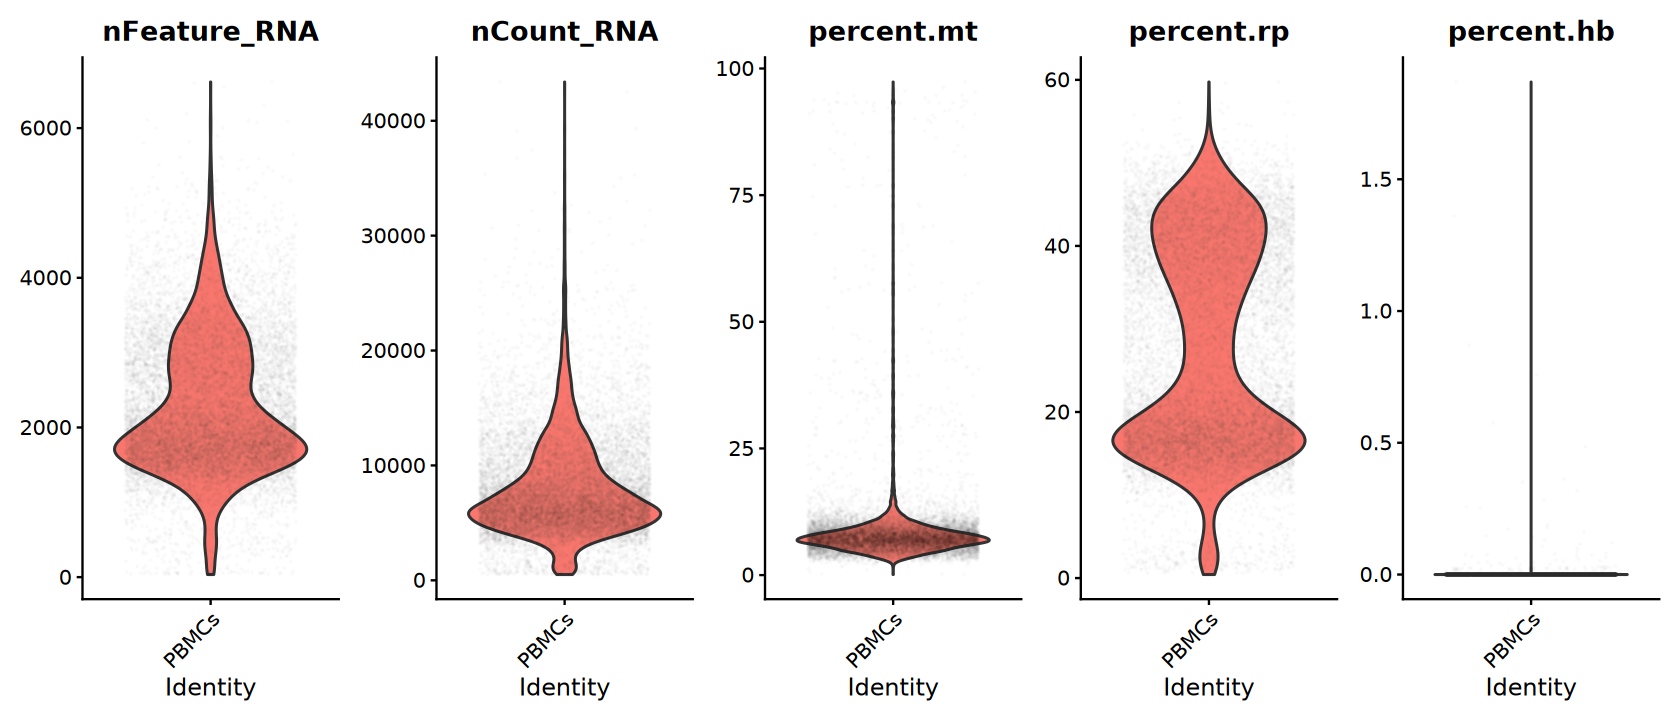

In [12]:
options(repr.plot.width = 14, repr.plot.height = 6)
VlnPlot(scrna, layer = "counts", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

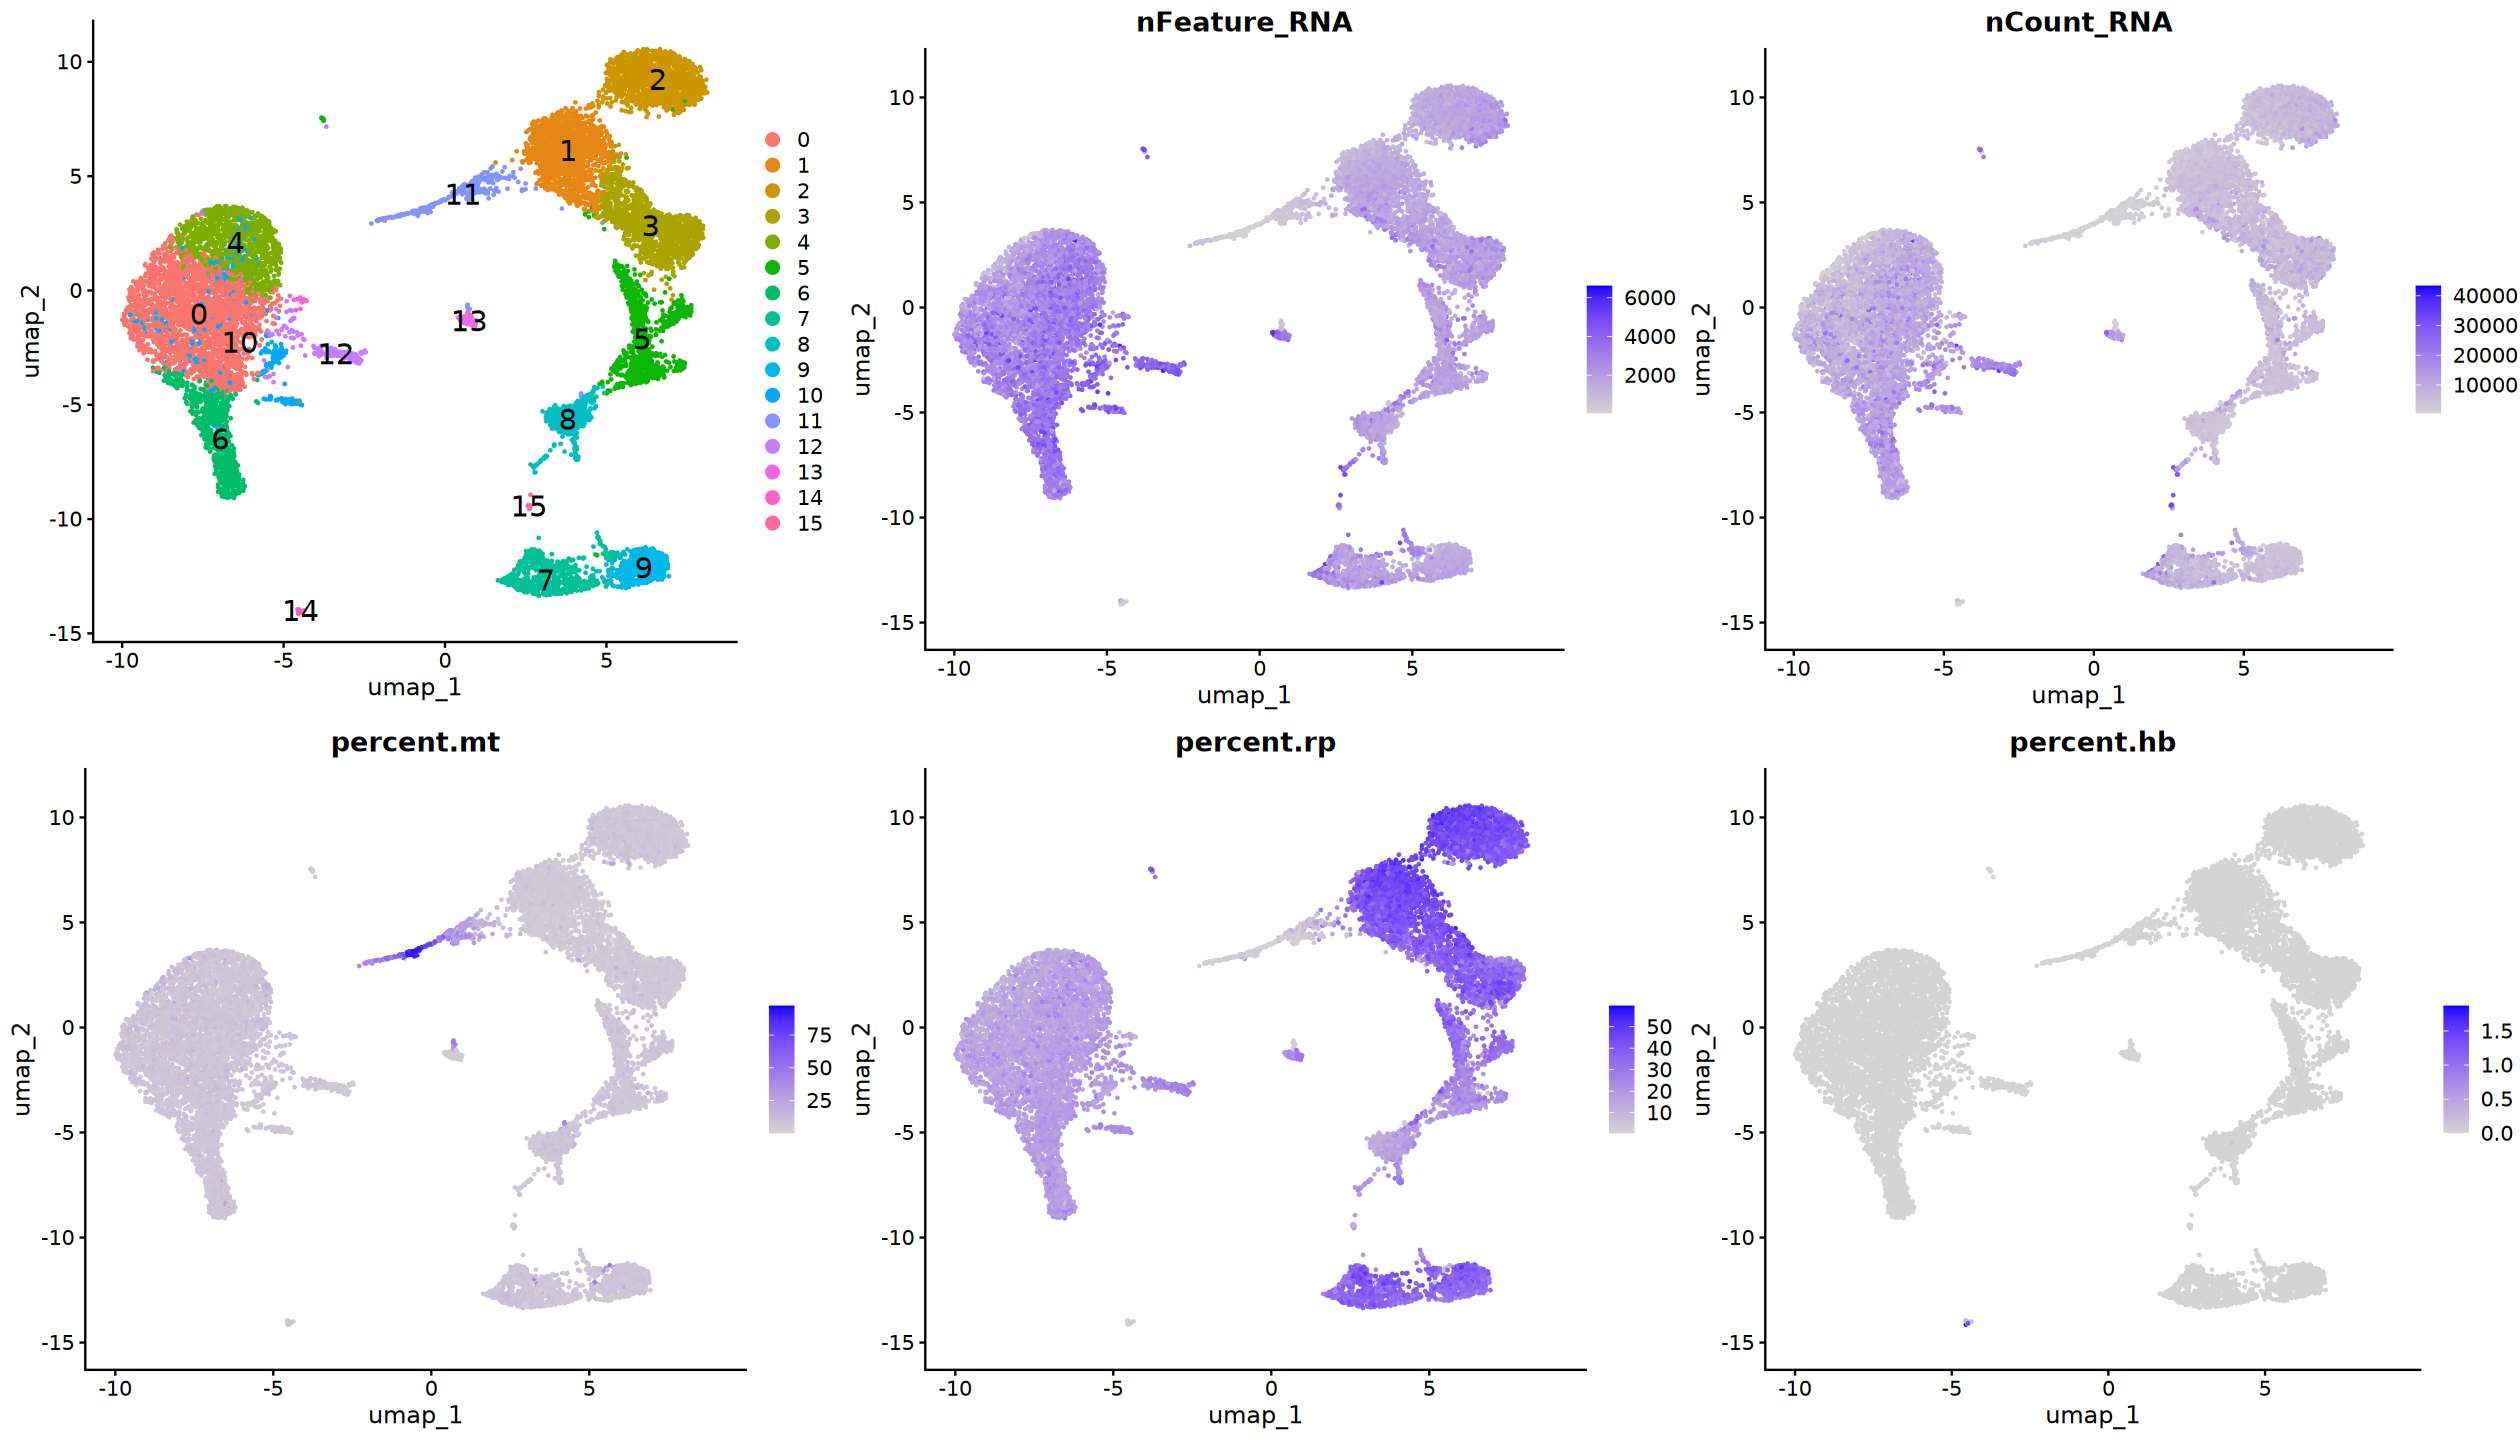

In [13]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, label.size = 6)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

## 3). Filtering Empty Droplets

Remove empty droplets and very low coverage cells to avoid affecting double cell recognition

ambient RNA

empty droplets

[DropletUtils](https://github.com/MarioniLab/DropletUtils): Loading from count matrices or molecule information files, identification of cells from empty droplets, removal of barcode-swapped pseudo-cells, and downsampling of the count matrix.

In [14]:
scrna <- subset(
    scrna, 
    subset = nFeature_RNA > 200 & percent.mt < 25)
scrna

An object of class Seurat 
22302 features across 11734 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)
 1 layer present: counts

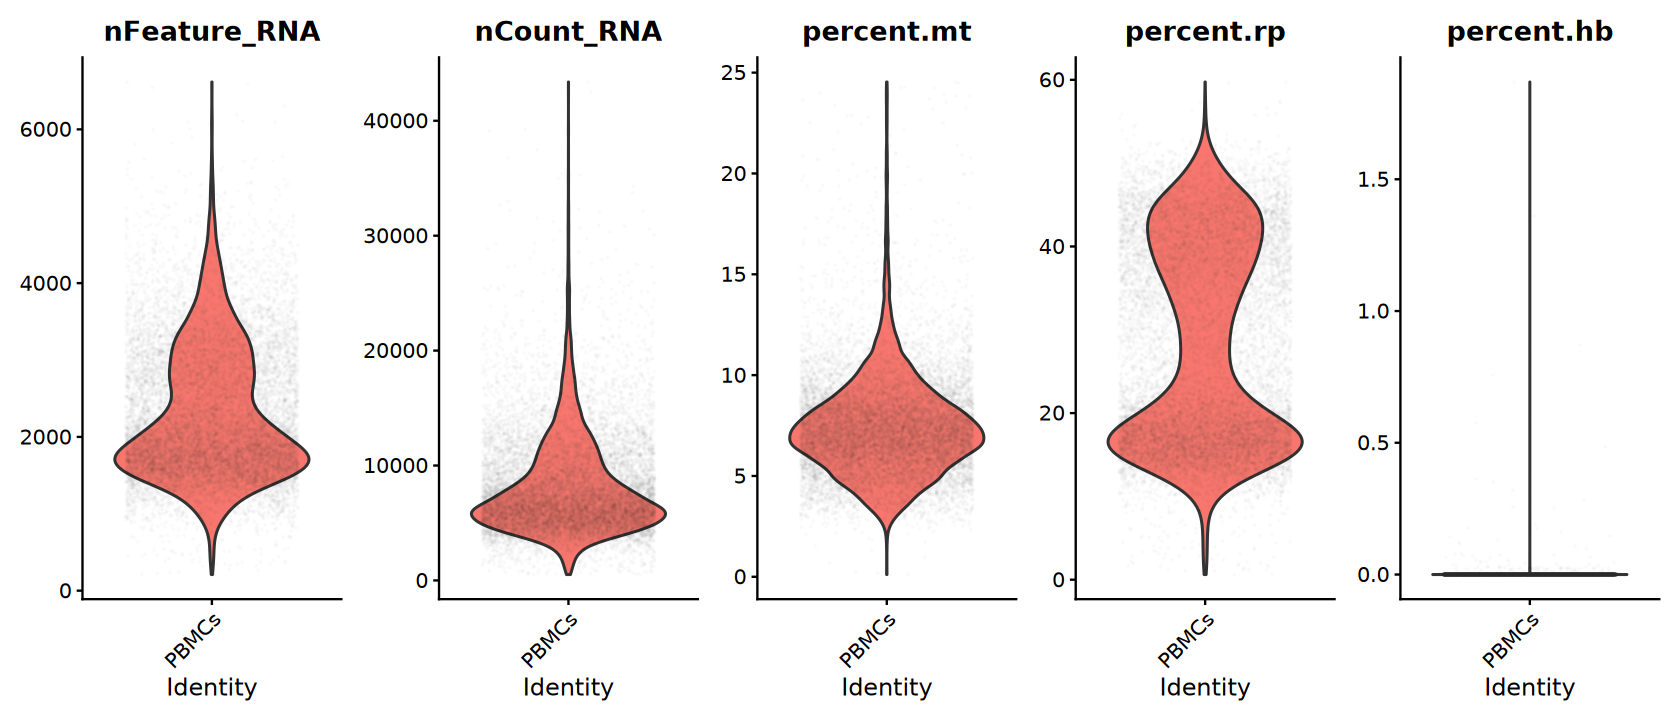

In [15]:
options(repr.plot.width = 14, repr.plot.height = 6)
VlnPlot(scrna, layer = "counts", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

## 4). Doublet Detection

- Xi, Nan Miles et al. Benchmarking Computational Doublet-Detection Methods for Single-Cell RNA Sequencing Data. Cell Systems, Volume 12, Issue 2, 176 - 194.e6

### a). [DoubletFinder](https://github.com/chris-mcginnis-ucsf/DoubletFinder)

1. Generate artificial doublets from existing scRNA-seq data
2. Pre-process merged real-artificial data
3. Perform PCA and use the PC distance matrix to find each cell's proportion of artificial k nearest neighbors (pANN)
4. Rank order and threshold pANN values according to the expected number of doublets

- McGinnis CS, Murrow LM, Gartner ZJ. DoubletFinder: Doublet Detection in Single-Cell RNA Sequencing Data Using Artificial Nearest Neighbors. Cell Syst. 2019 Apr 24;8(4):329-337.e4. doi: 10.1016/j.cels.2019.03.003.

In [16]:
suppressPackageStartupMessages(library(DoubletFinder))
# suppressPackageStartupMessages(library(DoubletFinderSilence))

In [17]:
sc.temp <- standard_preprocessing(scrna, ndim = 20)

In [18]:
# Performs pN-pK parameter sweeps on a 10,000-cell subset of
# a pre-processed Seurat object.
set.seed(1234)
sweep.res.list <- paramSweep(sc.temp, PCs = 1:20, sct = FALSE)

[1] "Creating artificial doublets for pN = 5%"
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



... (27 outputs left out)

Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.001..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."


In [19]:
# Summarizes results from doubletFinder::ParamSweep, 
# computing the bimodality coefficient across pN and pK parameter space.

# pK Identification (no ground-truth)
sweep.stats <- summarizeSweep(sweep.res.list, GT = FALSE)

# # pK Identification (ground-truth)
# gt.calls <- temp@meta.data[rownames(sweep.res.list[[1]]), "GT"].
# # When GT = TRUE, the function involves random sampling
# set.seed(1234)
# sweep.stats <- summarizeSweep(sweep.res.list, GT = TRUE, GT.calls = gt.calls)

NULL


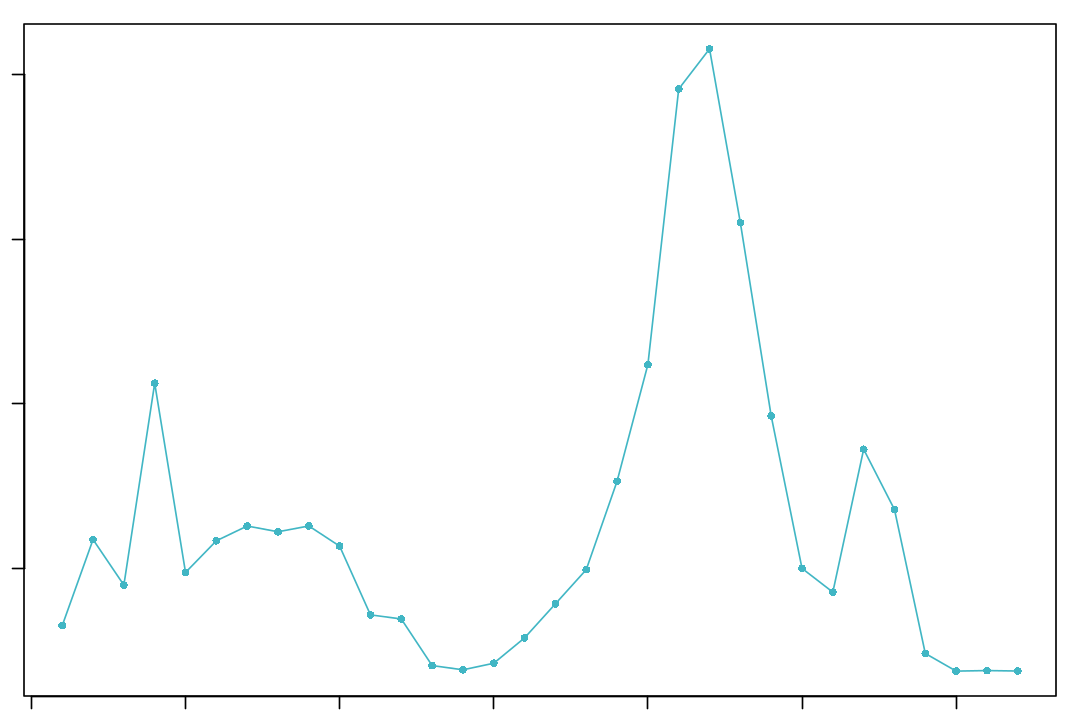

In [20]:
options(repr.plot.width = 9, repr.plot.height = 6)
# Computes and visualizes the mean-variance normalized
# bimodality coefficient (BCmvn) score for each pK value
# tested during doubletFinder_ParamSweep.
bcmvn <- find.pK(sweep.stats)

In [21]:
optimal.pK <- bcmvn$pK[which.max(bcmvn$BCmetric)] |> 
    as.vector() |> as.numeric()
message("optimal pK: ", optimal.pK)

optimal pK: 0.2



In [22]:
# Homotypic Doublet Proportion Estimate
# Leverages user-provided cell annotations to model 
# the proportion of homotypic doublets.
homotypic.prop <- modelHomotypic(sc.temp$seurat_clusters)

nCell <- length(Cells(sc.temp))
nExp <- round(nCell / 1000 * 0.008 * nCell)
nExp.adj <- round(nExp * (1 - homotypic.prop))

message("Estimated expected doublets (nExp): ", nExp.adj)

Estimated expected doublets (nExp): 983



In [23]:
set.seed(1234)
sc.temp <- doubletFinder(
    sc.temp, PCs = 1:20, pN = 0.25, 
    pK = optimal.pK, nExp = nExp.adj)

[1] "Creating 3911 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."


Normalizing layer: counts



[1] "Finding variable genes..."


Finding variable features for layer counts



[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Computing pANN..."
[1] "Classifying doublets.."


In [24]:
old_col <- c("pANN", "DF.classifications") |> 
    paste(0.25, optimal.pK, nExp.adj, sep = "_")

scrna$DoubletFinder.pANN <- sc.temp@meta.data[, old_col[1]]
scrna$DoubletFinder.class <- sc.temp@meta.data[, old_col[2]] |> 
    factor(levels = c("Singlet", "Doublet"))

In [25]:
table(scrna$DoubletFinder.class)


Singlet Doublet 
  10751     983 

### b). [scDblFinder](https://github.com/plger/scDblFinder)

scDblFinder() has two main modes of operation: cluster-based or not. Both perform quite well (see Germain et al., 2021). In general, we recommend the cluster-based approach in datasets with a very clear cluster structure, and the random approach in more complex datasets.

1. Reducing and clustering the data
2. Generating artificial doublets
3. Examining the k-nearest neighbors (kNN) of each cell
4. Training a classifier
5. Thresholding
6. Doublet origins and enrichments

- Germain PL, Lun A, Garcia Meixide C et al. Doublet identification in single-cell sequencing data using scDblFinder [version 2; peer review: 2 approved]. F1000Research 2022, 10:979 (https://doi.org/10.12688/f1000research.73600.2)

In [26]:
suppressPackageStartupMessages(library(scDblFinder))

In [27]:
sce <- standard_preprocessing(scrna, ndim = 20) |>
    as.SingleCellExperiment()
sce

class: SingleCellExperiment 
dim: 22302 11734 
metadata(0):
assays(2): counts logcounts
rownames(22302): AL627309.1 AL627309.3 ... AC233755.1 AC007325.4
rowData names(0):
colnames(11734): AAACCCAAGGCCCAAA-1 AAACCCAAGTAATACG-1 ...
  TTTGTTGTCTACACAG-1 TTTGTTGTCTCATTAC-1
colData names(11): orig.ident nCount_RNA ... seurat_clusters ident
reducedDimNames(3): PCA UMAP TSNE
mainExpName: RNA
altExpNames(0):

In [28]:
set.seed(1234)
# # random approach in more complex datasets.
# sce <- scDblFinder(sce, verbose = FALSE)
# cluster-based approach in datasets with a very clear cluster structure.
sce <- scDblFinder(
    sce, clusters = "seurat_clusters", verbose = FALSE)
# # normal scater-based normalization and PCA
# sce <- scDblFinder(
#     LayerData(scrna, assay = "RNA", layer = "counts"), 
#     clusters = "seurat_clusters", verbose = FALSE)

In [29]:
scrna$scDblFinder.score <- colData(sce)$scDblFinder.score
scrna$scDblFinder.class <- colData(sce)$scDblFinder.class

In [30]:
table(scrna$scDblFinder.class)


singlet doublet 
  10832     902 

### c). [DoubletDecon](https://github.com/EDePasquale/DoubletDecon)

In [31]:
# suppressPackageStartupMessages(library(DoubletDecon))
# # Seurat Object V3

In [32]:
# newFiles <- Improved_Seurat_Pre_Process(
#     scrna, num_genes = 50, write_files = FALSE)
# results <- Main_Doublet_Decon(
#     rawDataFile = newFiles$newExpressionFile, 
#     groupsFile = newFiles$newGroupsFile, 
#     filename = filename, location = location, 
#     fullDataFile = NULL, removeCC = FALSE, 
#     species = "hsa", rhop = 1.1, write = TRUE, 
#     PMF = TRUE, useFull = FALSE, heatmap = FALSE, 
#     centroids = TRUE, num_doubs = 100, only50 = FALSE,
#     min_uniq = 4, nCores = -1)

### d). [scds](https://github.com/kostkalab/scds)

In [33]:
# suppressPackageStartupMessages(library(scds))
# # xgboost An older version may be required.

In [34]:
# sce <- as.SingleCellExperiment(scrna)
# # doublet detection using co-expression based doublet scoring
# sce <- cxds(sce, retRes = TRUE, verb = FALSE)
# # doublet detection using binary classification based doublet scoring
# sce <- bcds(sce, retRes = TRUE, verb = FALSE)
# # Combine both annotations into a hybrid annotation
# sce <- cxds_bcds_hybrid(sce)
# # Doublet scores are now available via colData:
# colData(sce)

### Filtering

In [35]:
sc.temp <- standard_preprocessing(scrna, ndim = 20)

In [36]:
table(scDblFinder = sc.temp$scDblFinder.class, 
      DoubletFinder = sc.temp$DoubletFinder.class)

           DoubletFinder
scDblFinder Singlet Doublet
    singlet   10295     537
    doublet     456     446

In [37]:
sc.temp$isDoublet <- apply(
    sc.temp@meta.data[, c("scDblFinder.class", "DoubletFinder.class")],
    1, function(x) paste(x, collapse = "_")) |> as.factor()

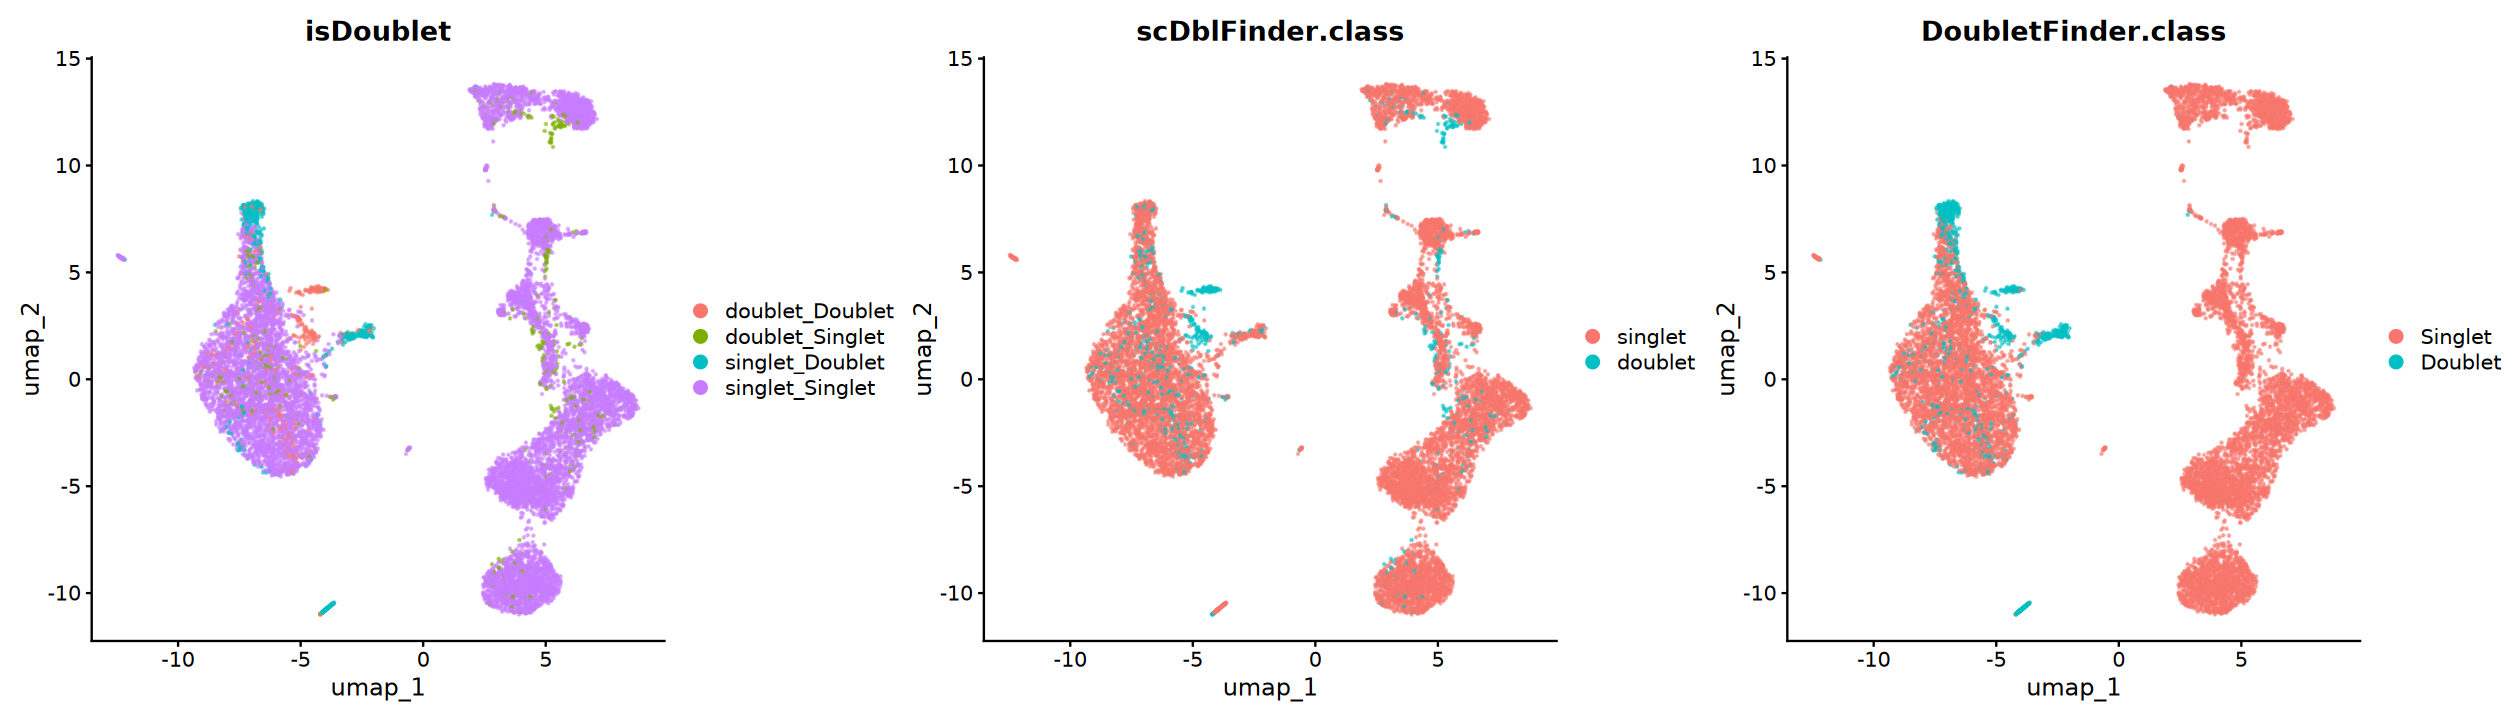

In [38]:
options(repr.plot.width = 21, repr.plot.height = 6)
DimPlot(sc.temp, reduction = "umap", 
        group.by = c("isDoublet", "scDblFinder.class", "DoubletFinder.class"),
        alpha = 0.5, pt.size = 0.1, ncol = 3)

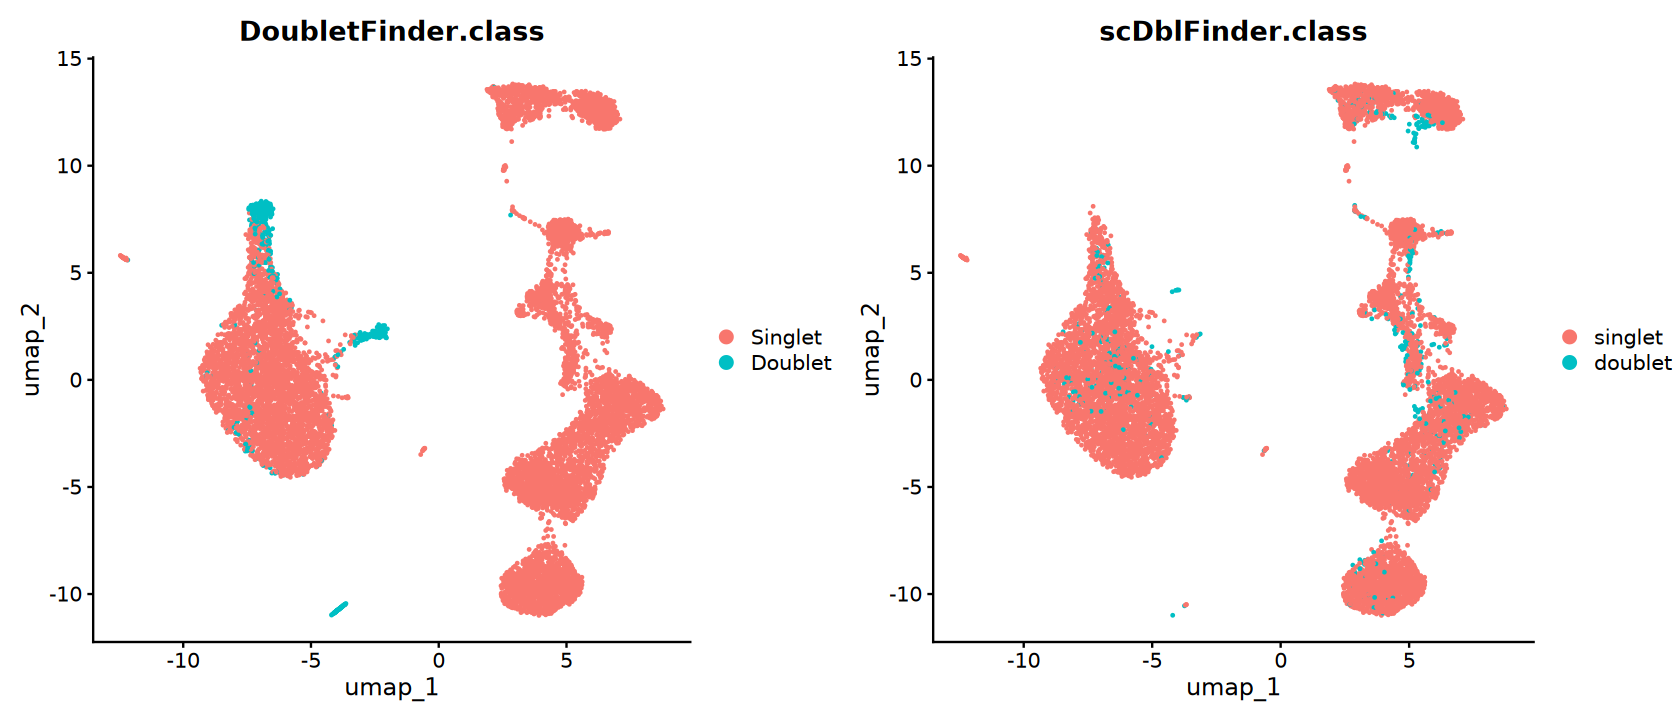

In [39]:
p1 <- DimPlot(
    subset(sc.temp, subset = scDblFinder.class == "singlet"),
    reduction = "umap", group.by = "DoubletFinder.class")
p2 <- DimPlot(
    subset(sc.temp, subset = DoubletFinder.class == "Singlet"), 
    reduction = "umap", group.by = "scDblFinder.class")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [40]:
scrna <- subset(
    scrna, 
    subset = DoubletFinder.class == "Singlet" & 
        scDblFinder.class == "singlet")
scrna

An object of class Seurat 
22302 features across 10295 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)
 1 layer present: counts

## 5). Visualizate Metrics

In [41]:
sc.temp <- standard_preprocessing(scrna, ndim = 20)

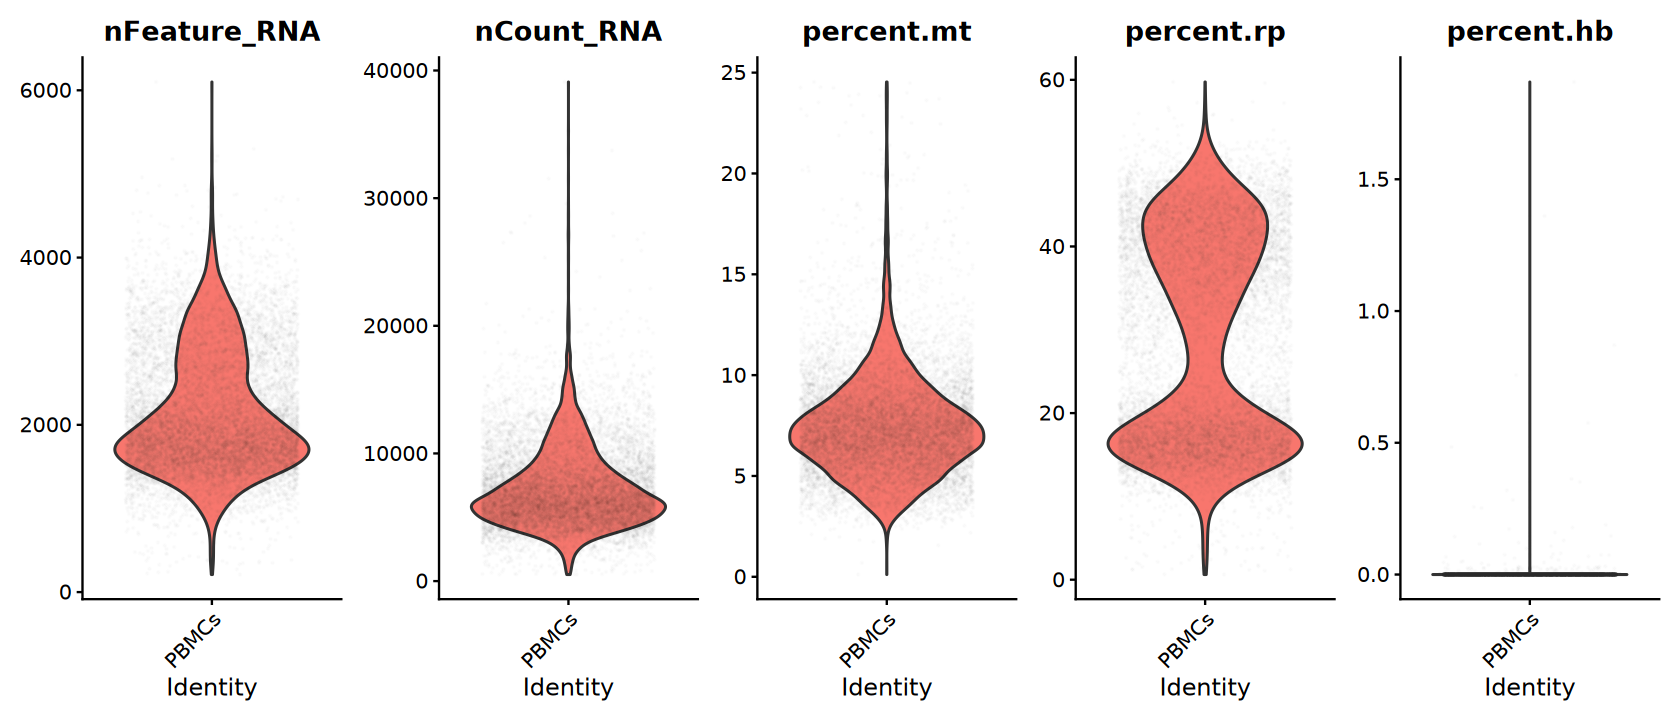

In [42]:
options(repr.plot.width = 14, repr.plot.height = 6)
VlnPlot(scrna, layer = "counts", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt",
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

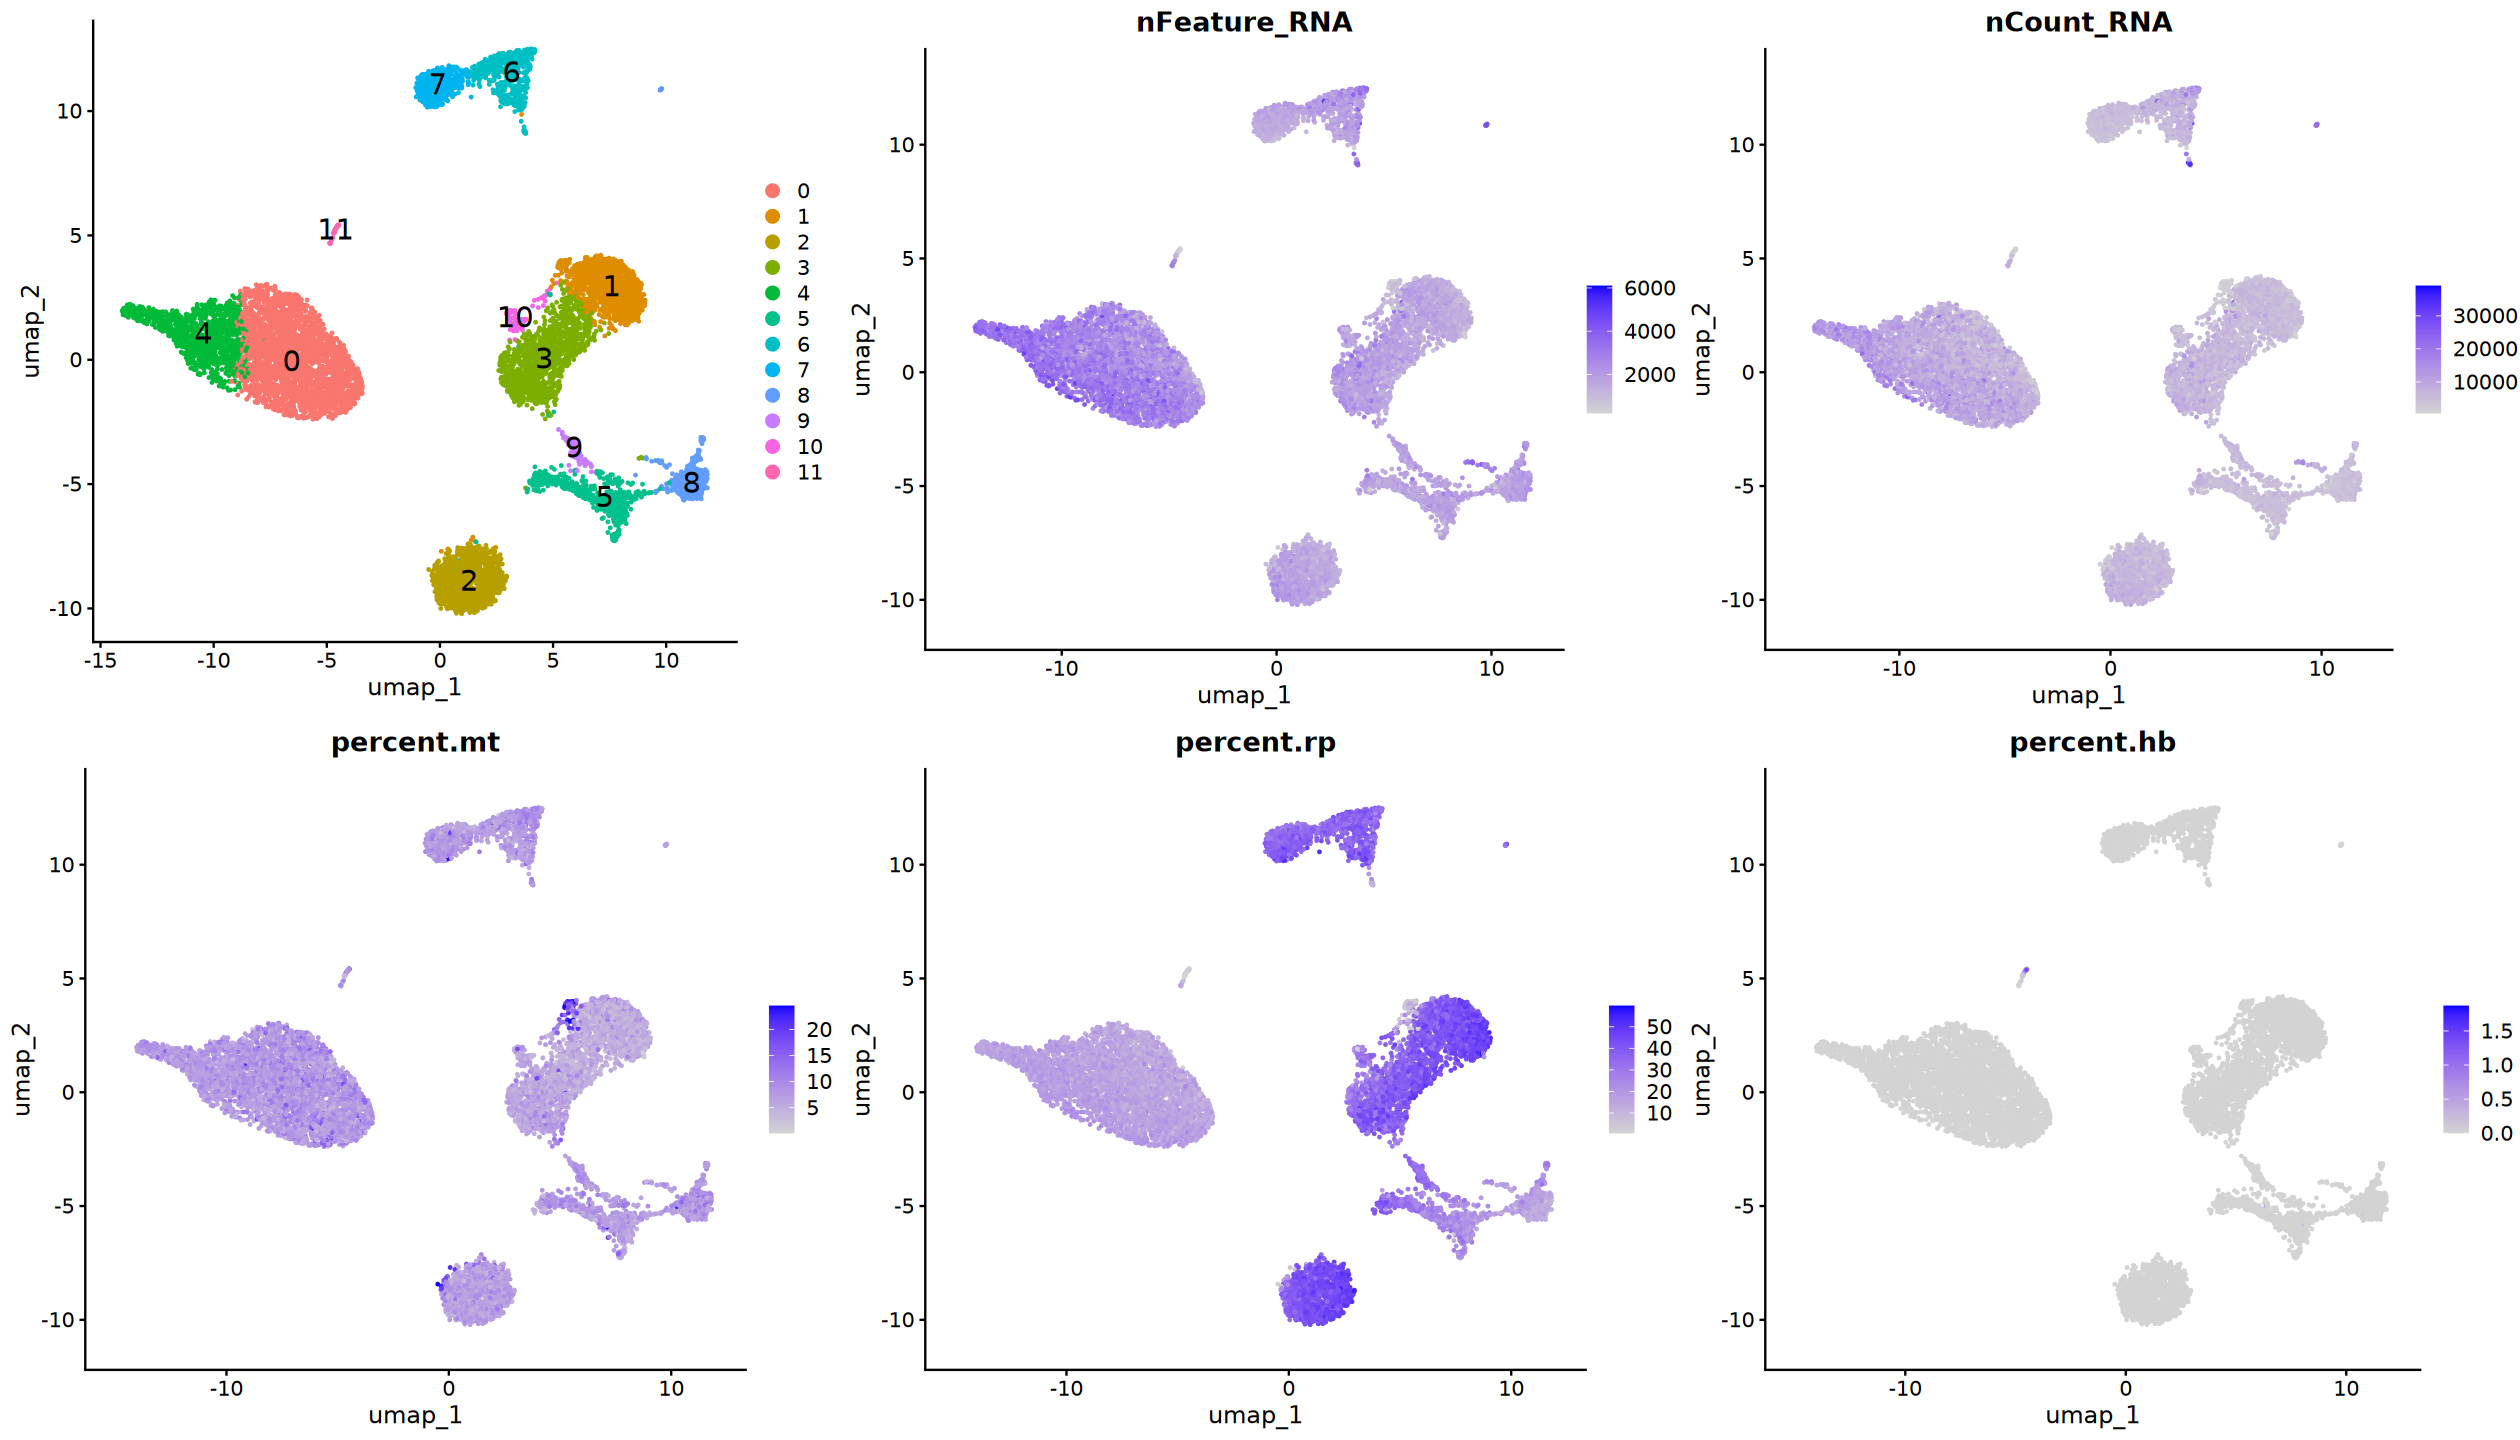

In [43]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, label.size = 6)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

In [44]:
summary(sc.temp@meta.data[, c("nFeature_RNA", "nCount_RNA", "percent.mt")])

  nFeature_RNA    nCount_RNA      percent.mt     
 Min.   : 210   Min.   :  514   Min.   : 0.1129  
 1st Qu.:1608   1st Qu.: 5130   1st Qu.: 5.8165  
 Median :1958   Median : 6568   Median : 7.1713  
 Mean   :2140   Mean   : 7254   Mean   : 7.4433  
 3rd Qu.:2644   3rd Qu.: 8740   3rd Qu.: 8.6437  
 Max.   :6099   Max.   :39100   Max.   :24.5345  

In [45]:
# Median Absolute Deviation (MAD)
calculate_mad_threshold <- function(
    metric, nmads = 3) {
    
    metric <- log2(metric)
    median_x <- median(metric)
    mad_x <- mad(metric)
    
    lower_bound <- median_x - nmads * mad_x
    upper_bound <- median_x + nmads * mad_x

    return(c(lower_bound = round(2^lower_bound), 
             upper_bound = round(2^upper_bound)))
}

In [46]:
nCount_threshold <- calculate_mad_threshold(sc.temp$nCount_RNA)
cat(sprintf("Counts: Upper: %d, Lower: %d\n", 
            nCount_threshold["upper_bound"], 
            nCount_threshold["lower_bound"]))

nFeature_threshold <- calculate_mad_threshold(sc.temp$nFeature_RNA)
cat(sprintf("Features: Upper: %d, Lower: %d\n", 
            nFeature_threshold["upper_bound"], 
            nFeature_threshold["lower_bound"]))

Counts: Upper: 21309, Lower: 2024
Features: Upper: 5520, Lower: 695


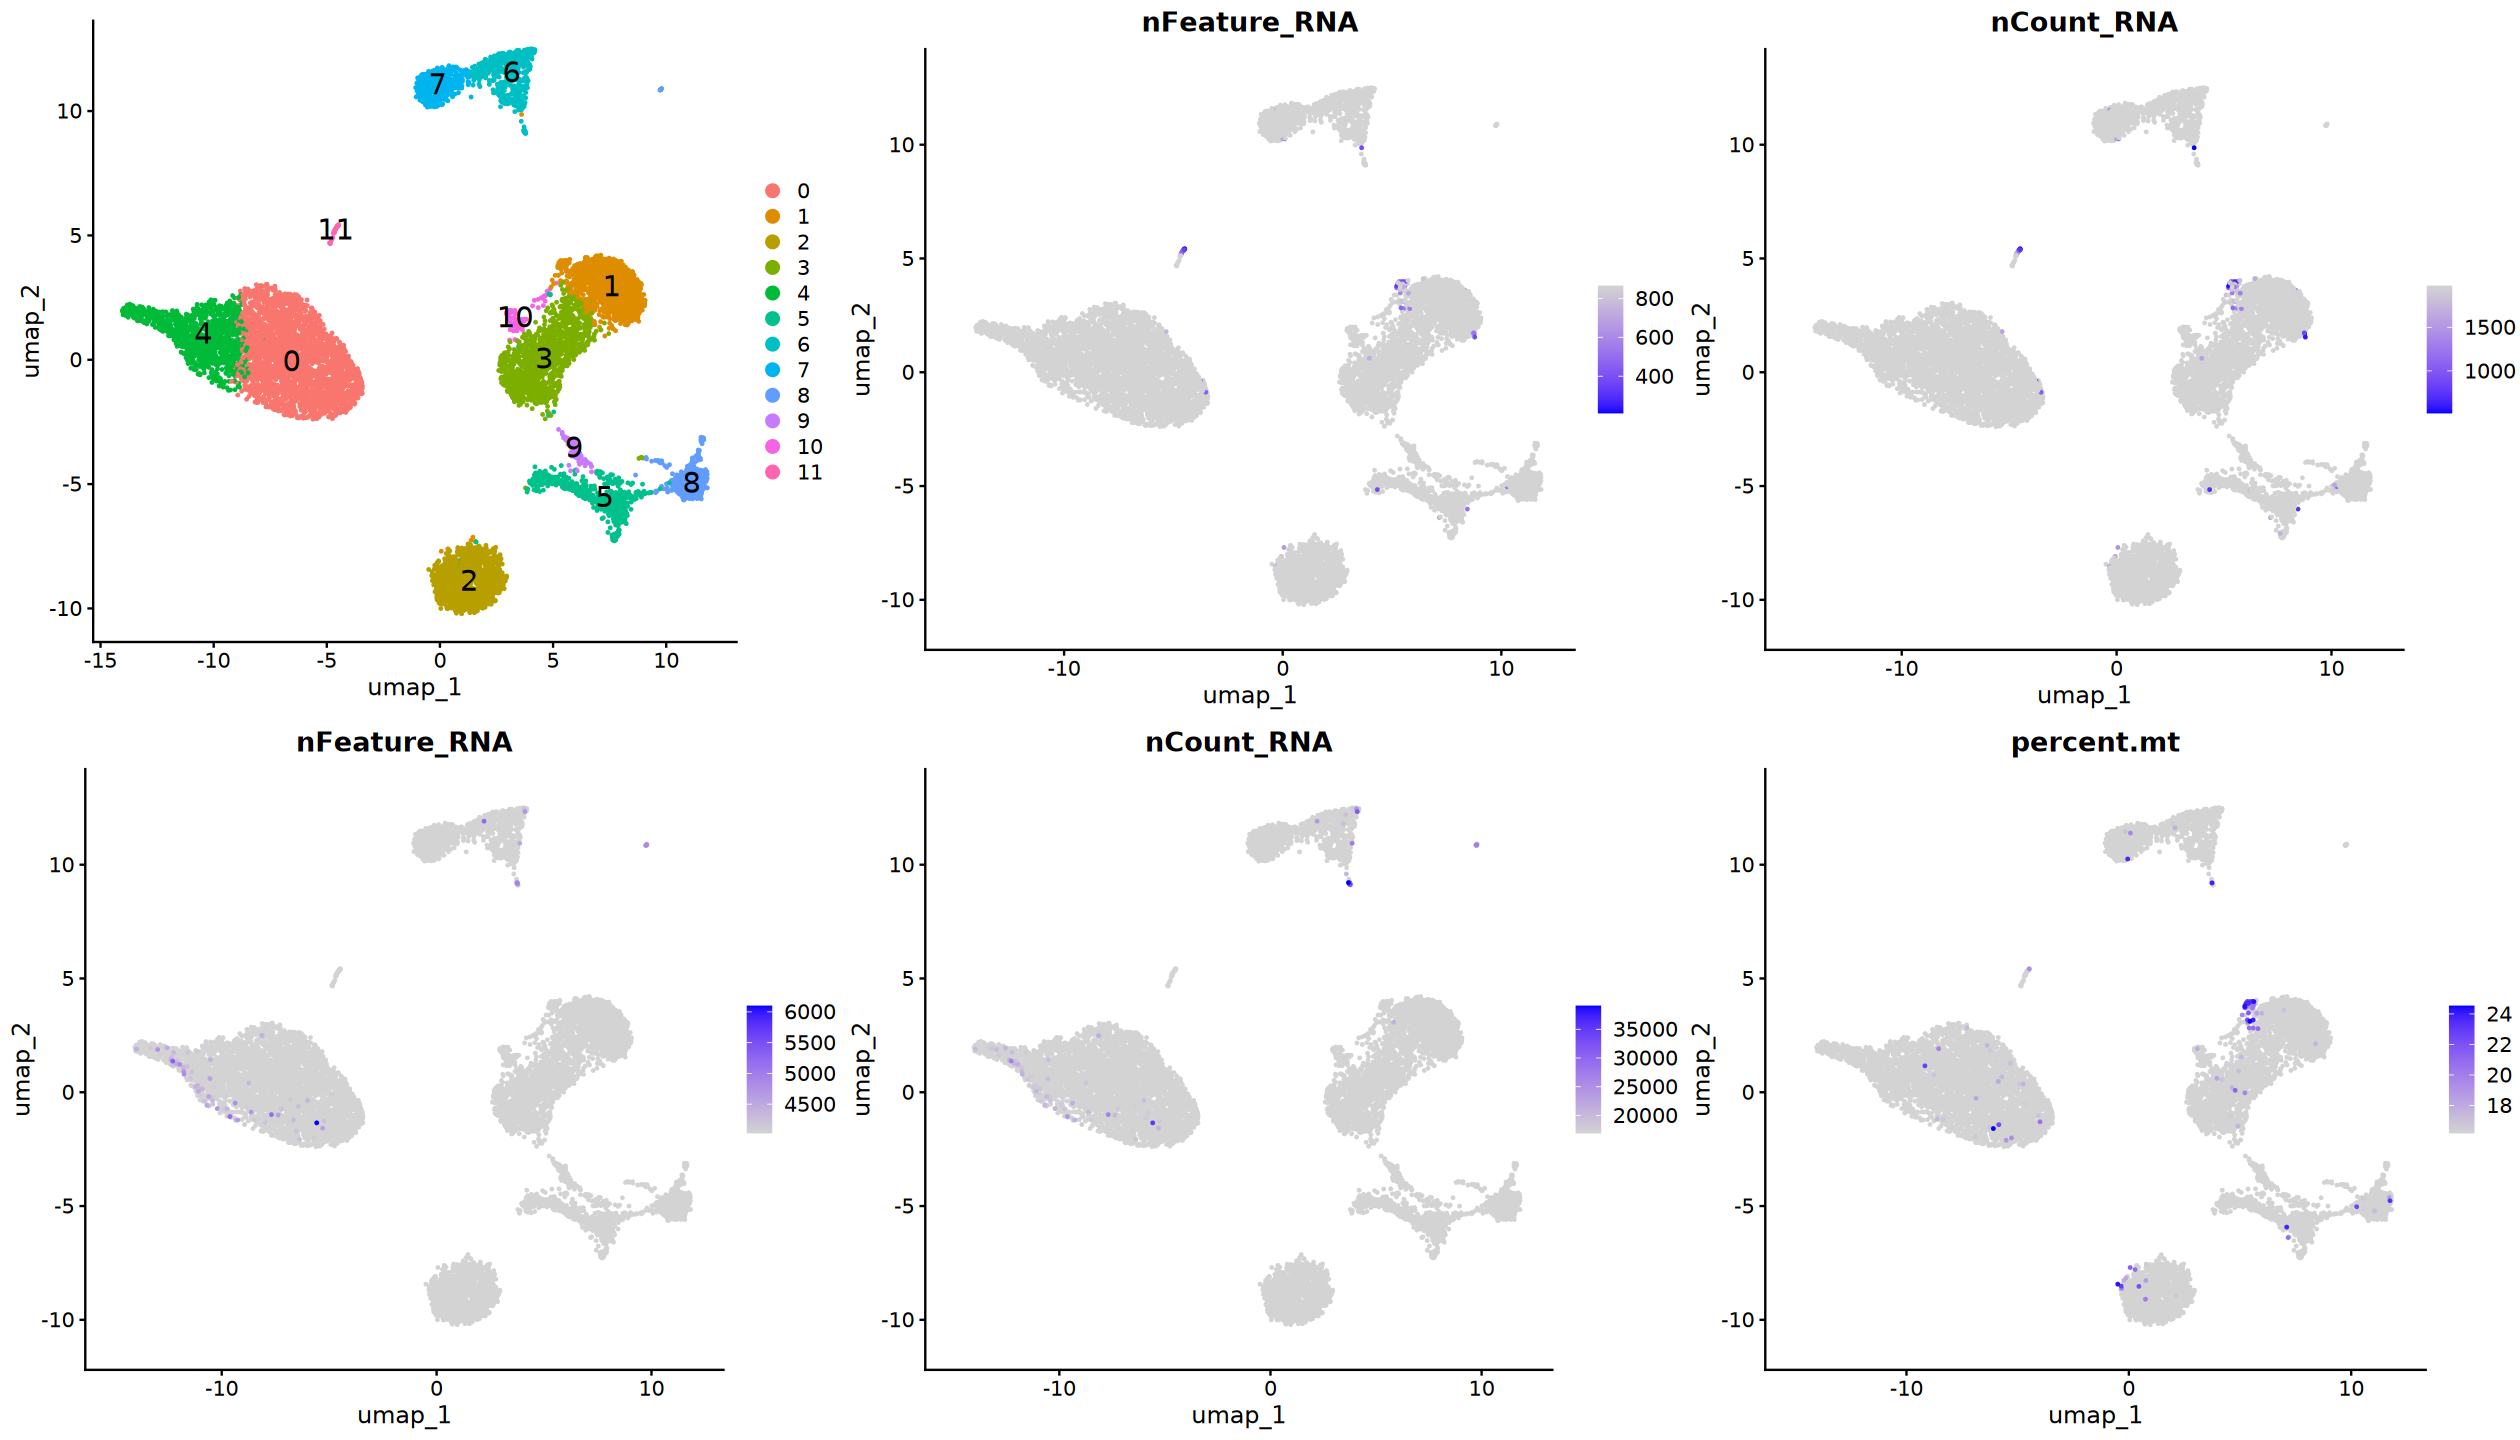

In [47]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE,
    label.size = 6)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap",
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt"),
    min.cutoff = "q99", order = TRUE, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3, byrow = TRUE)

## 6). Filtering Low-quality Cells

In [48]:
scrna <- subset(
    scrna, 
    subset = nFeature_RNA > 600 & 
        nCount_RNA > 1000 & nCount_RNA < 2e4 & 
        percent.mt < 15 & percent.hb < 1)
scrna

An object of class Seurat 
22302 features across 10087 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)
 1 layer present: counts

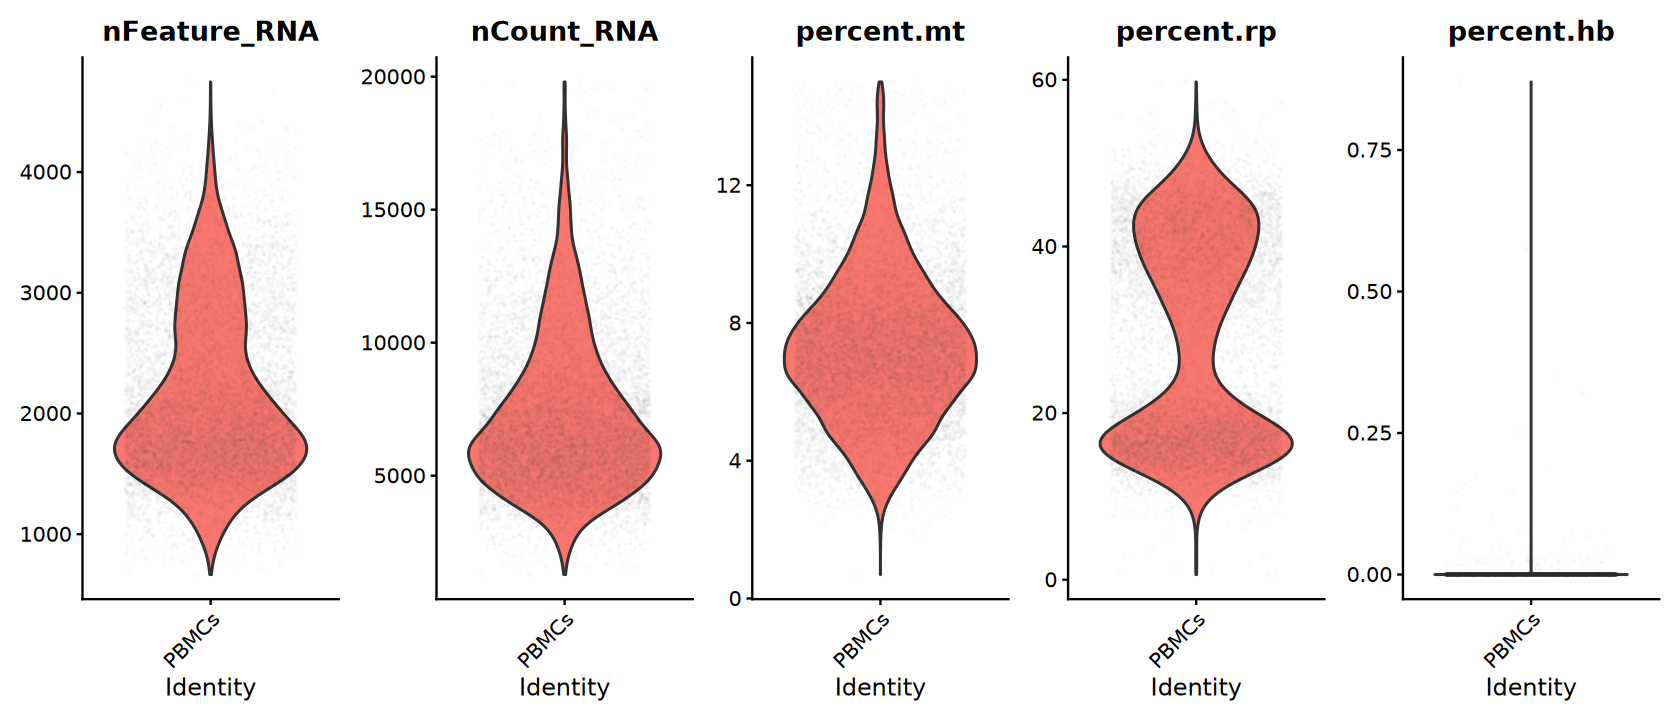

In [49]:
options(repr.plot.width = 14, repr.plot.height = 6)
VlnPlot(scrna, layer = "counts", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt",
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

## 7). Evaluating Noise

### a). Cell cycle effect

Seurat suggest regressing out the difference between the G2M and S phase scores. This means that signals separating non-cycling cells and cycling cells will be maintained, but differences in cell cycle phase among proliferating cells will be regressed out of the data.

```R
scrna$CC.Difference <- scrna$S.Score - scrna$G2M.Score
scrna <- ScaleData(scrna, features = Features(scrna), vars.to.regress = "CC.Difference", verbose = FALSE)
```

In [50]:
str(cc.genes)

List of 2
 $ s.genes  : chr [1:43] "MCM5" "PCNA" "TYMS" "FEN1" ...
 $ g2m.genes: chr [1:54] "HMGB2" "CDK1" "NUSAP1" "UBE2C" ...


In [51]:
scrna <- NormalizeData(scrna, verbose = FALSE) |> 
    CellCycleScoring(s.features = cc.genes$s.genes,
                     g2m.features = cc.genes$g2m.genes)

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


### b). Cell dissociation effect

- van den Brink, S., Sage, F., Vértesy, Á. et al. Single-cell sequencing reveals dissociation-induced gene expression in tissue subpopulations. Nat Methods 14, 935–936 (2017). https://doi.org/10.1038/nmeth.4437

In [52]:
dissociation_genes <- readLines(
    "~/data1/single_cell_dataset/reference_infomation/dissociation_genes.txt")
str(dissociation_genes)

 chr [1:140] "Actg1" "Btg1" "Cxcl1" "Dnajb4" "Errfi1" "H3f3b" "Hspb1" ...


In [53]:
scrna <- AddModuleScore(
    scrna, name = "Dissociation.Score", 
    features = list(
        dissociationGenes = toupper(dissociation_genes)))
# rename
scrna@meta.data <- scrna@meta.data |> 
    dplyr::rename("Dis.Score" = "Dissociation.Score1")

Warning message:
“The following features are not present in the object: ANKRD1, CYR61, FAM132B, MT1, DCN, MT2, CCRN4L, NPPC, not searching for symbol synonyms”


### c). Batch effect

In [54]:
sc.temp <- standard_preprocessing(scrna, ndim = 20)

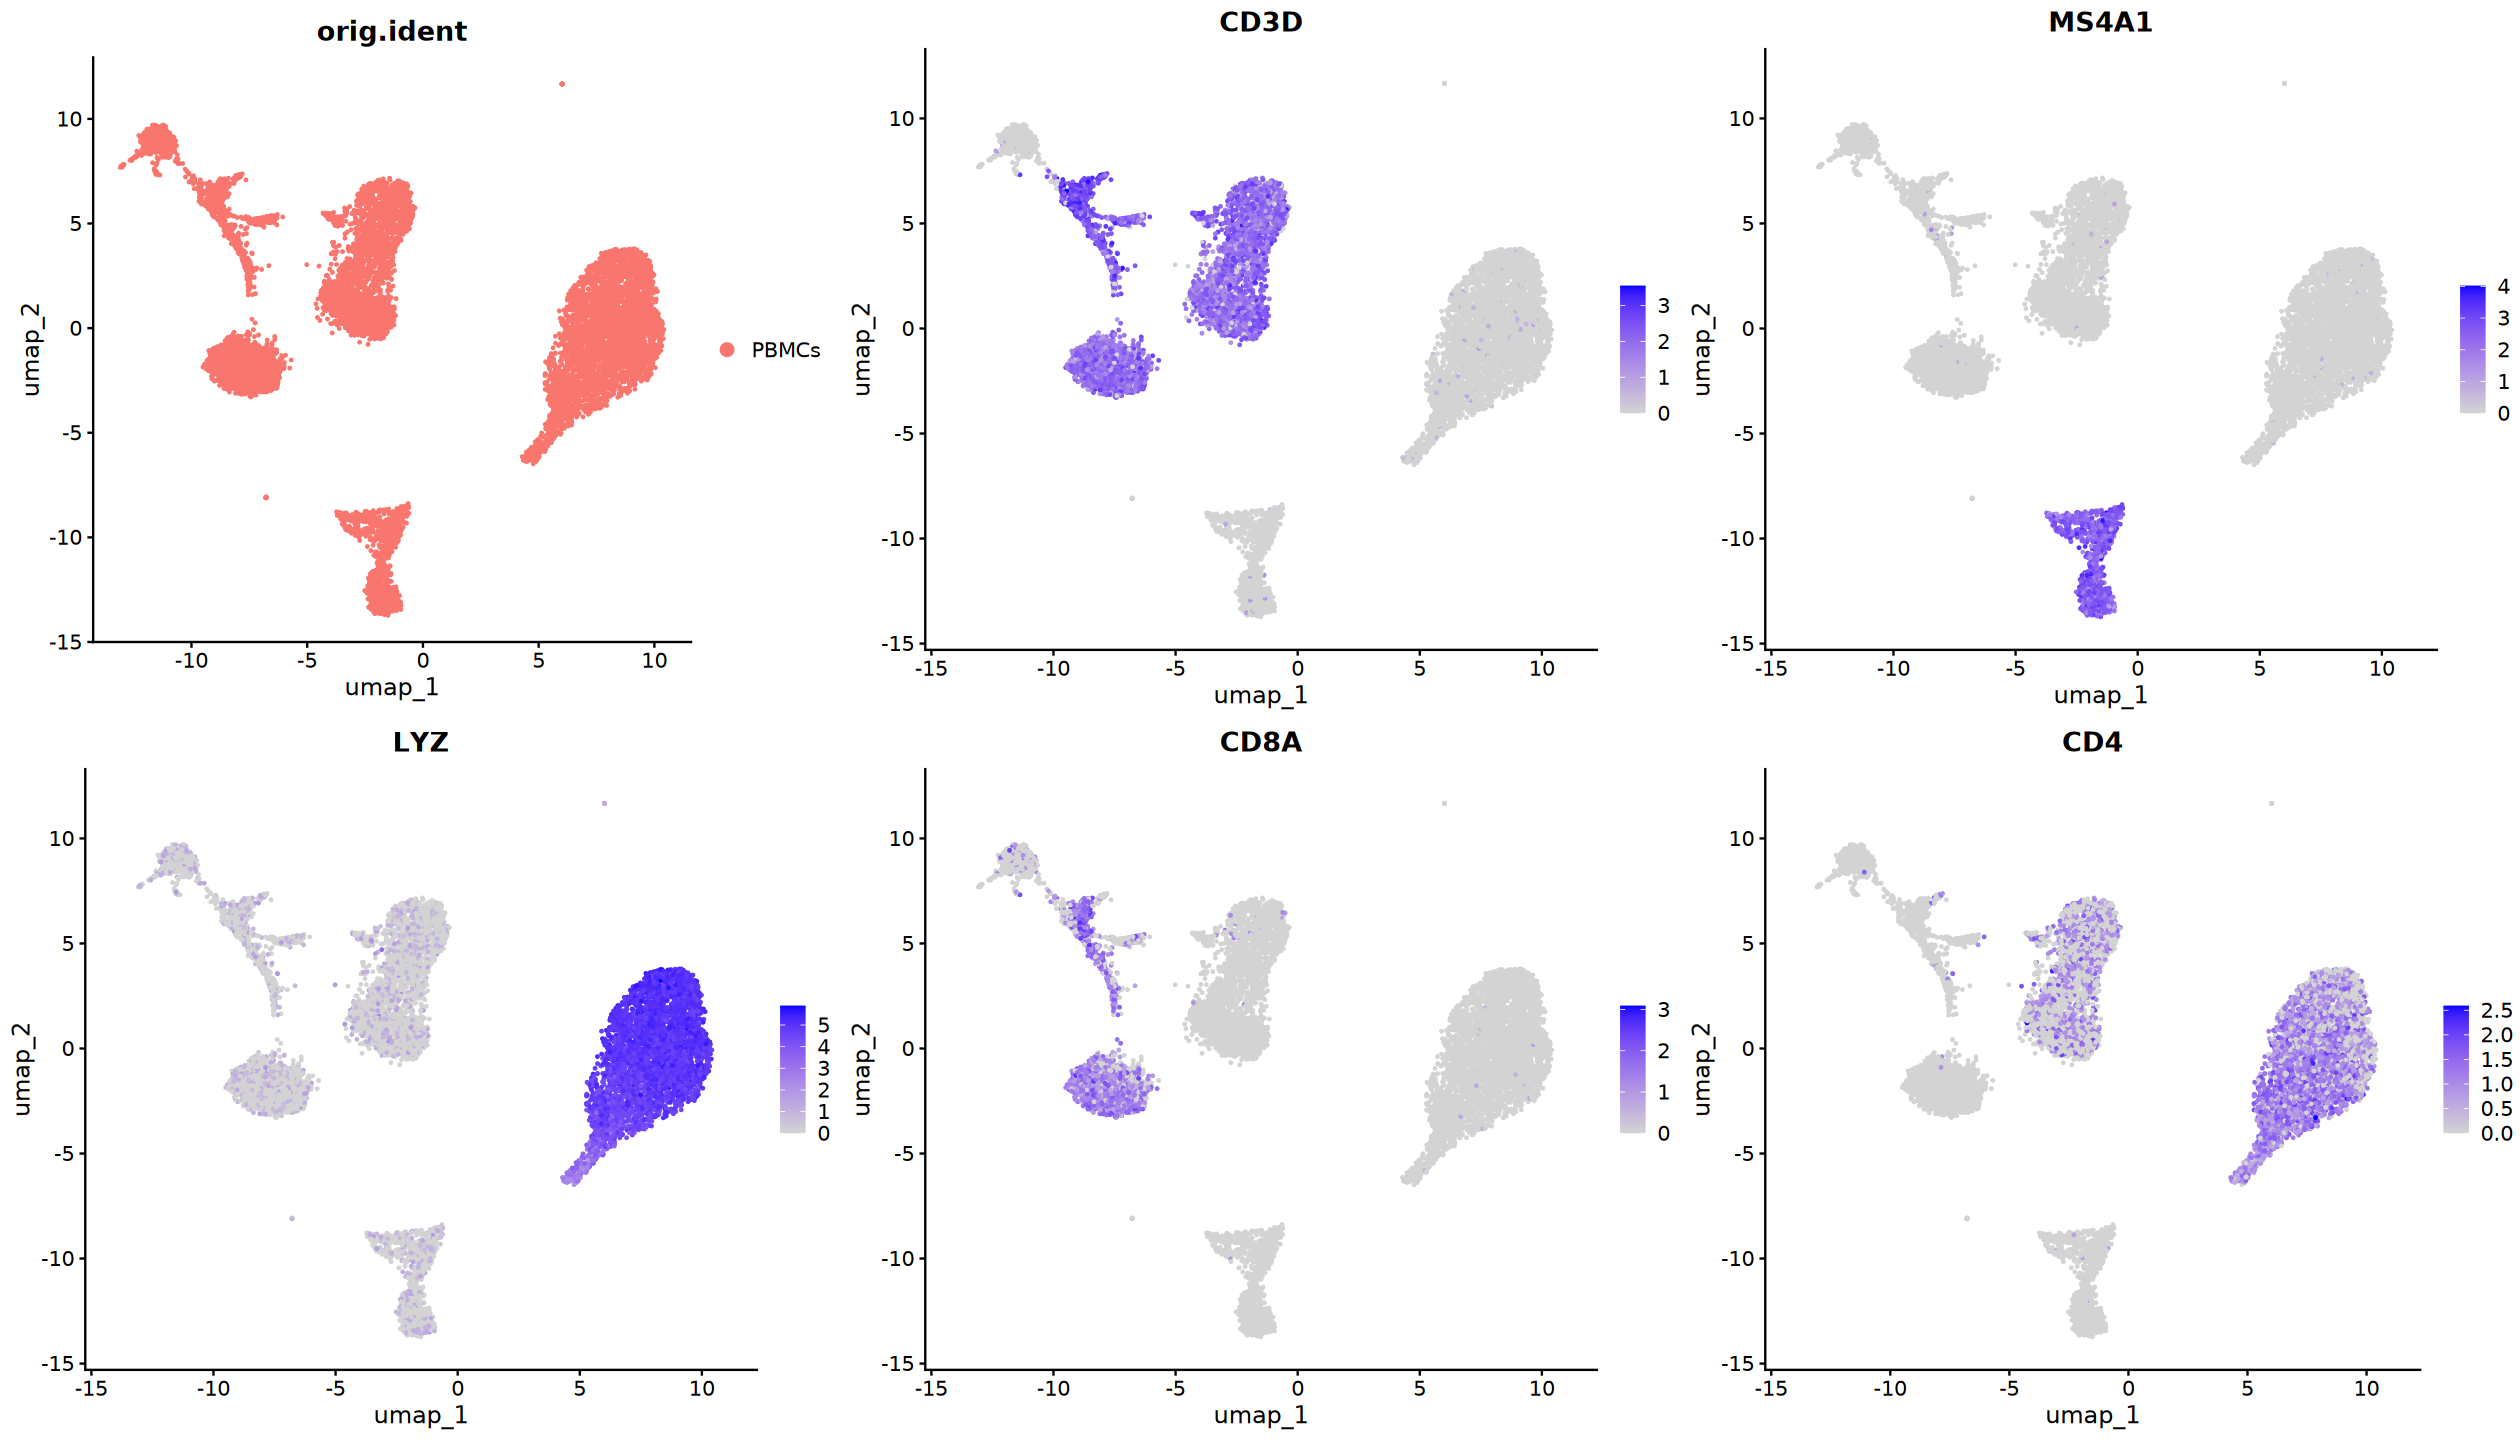

In [55]:
geneset <- c("CD3D", "MS4A1", "LYZ", "CD8A", "CD4")
p1 <- DimPlot(
    sc.temp, group.by = "orig.ident", 
    reduction = "umap", label = FALSE)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", features = geneset,
    combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

## 8). Visualization

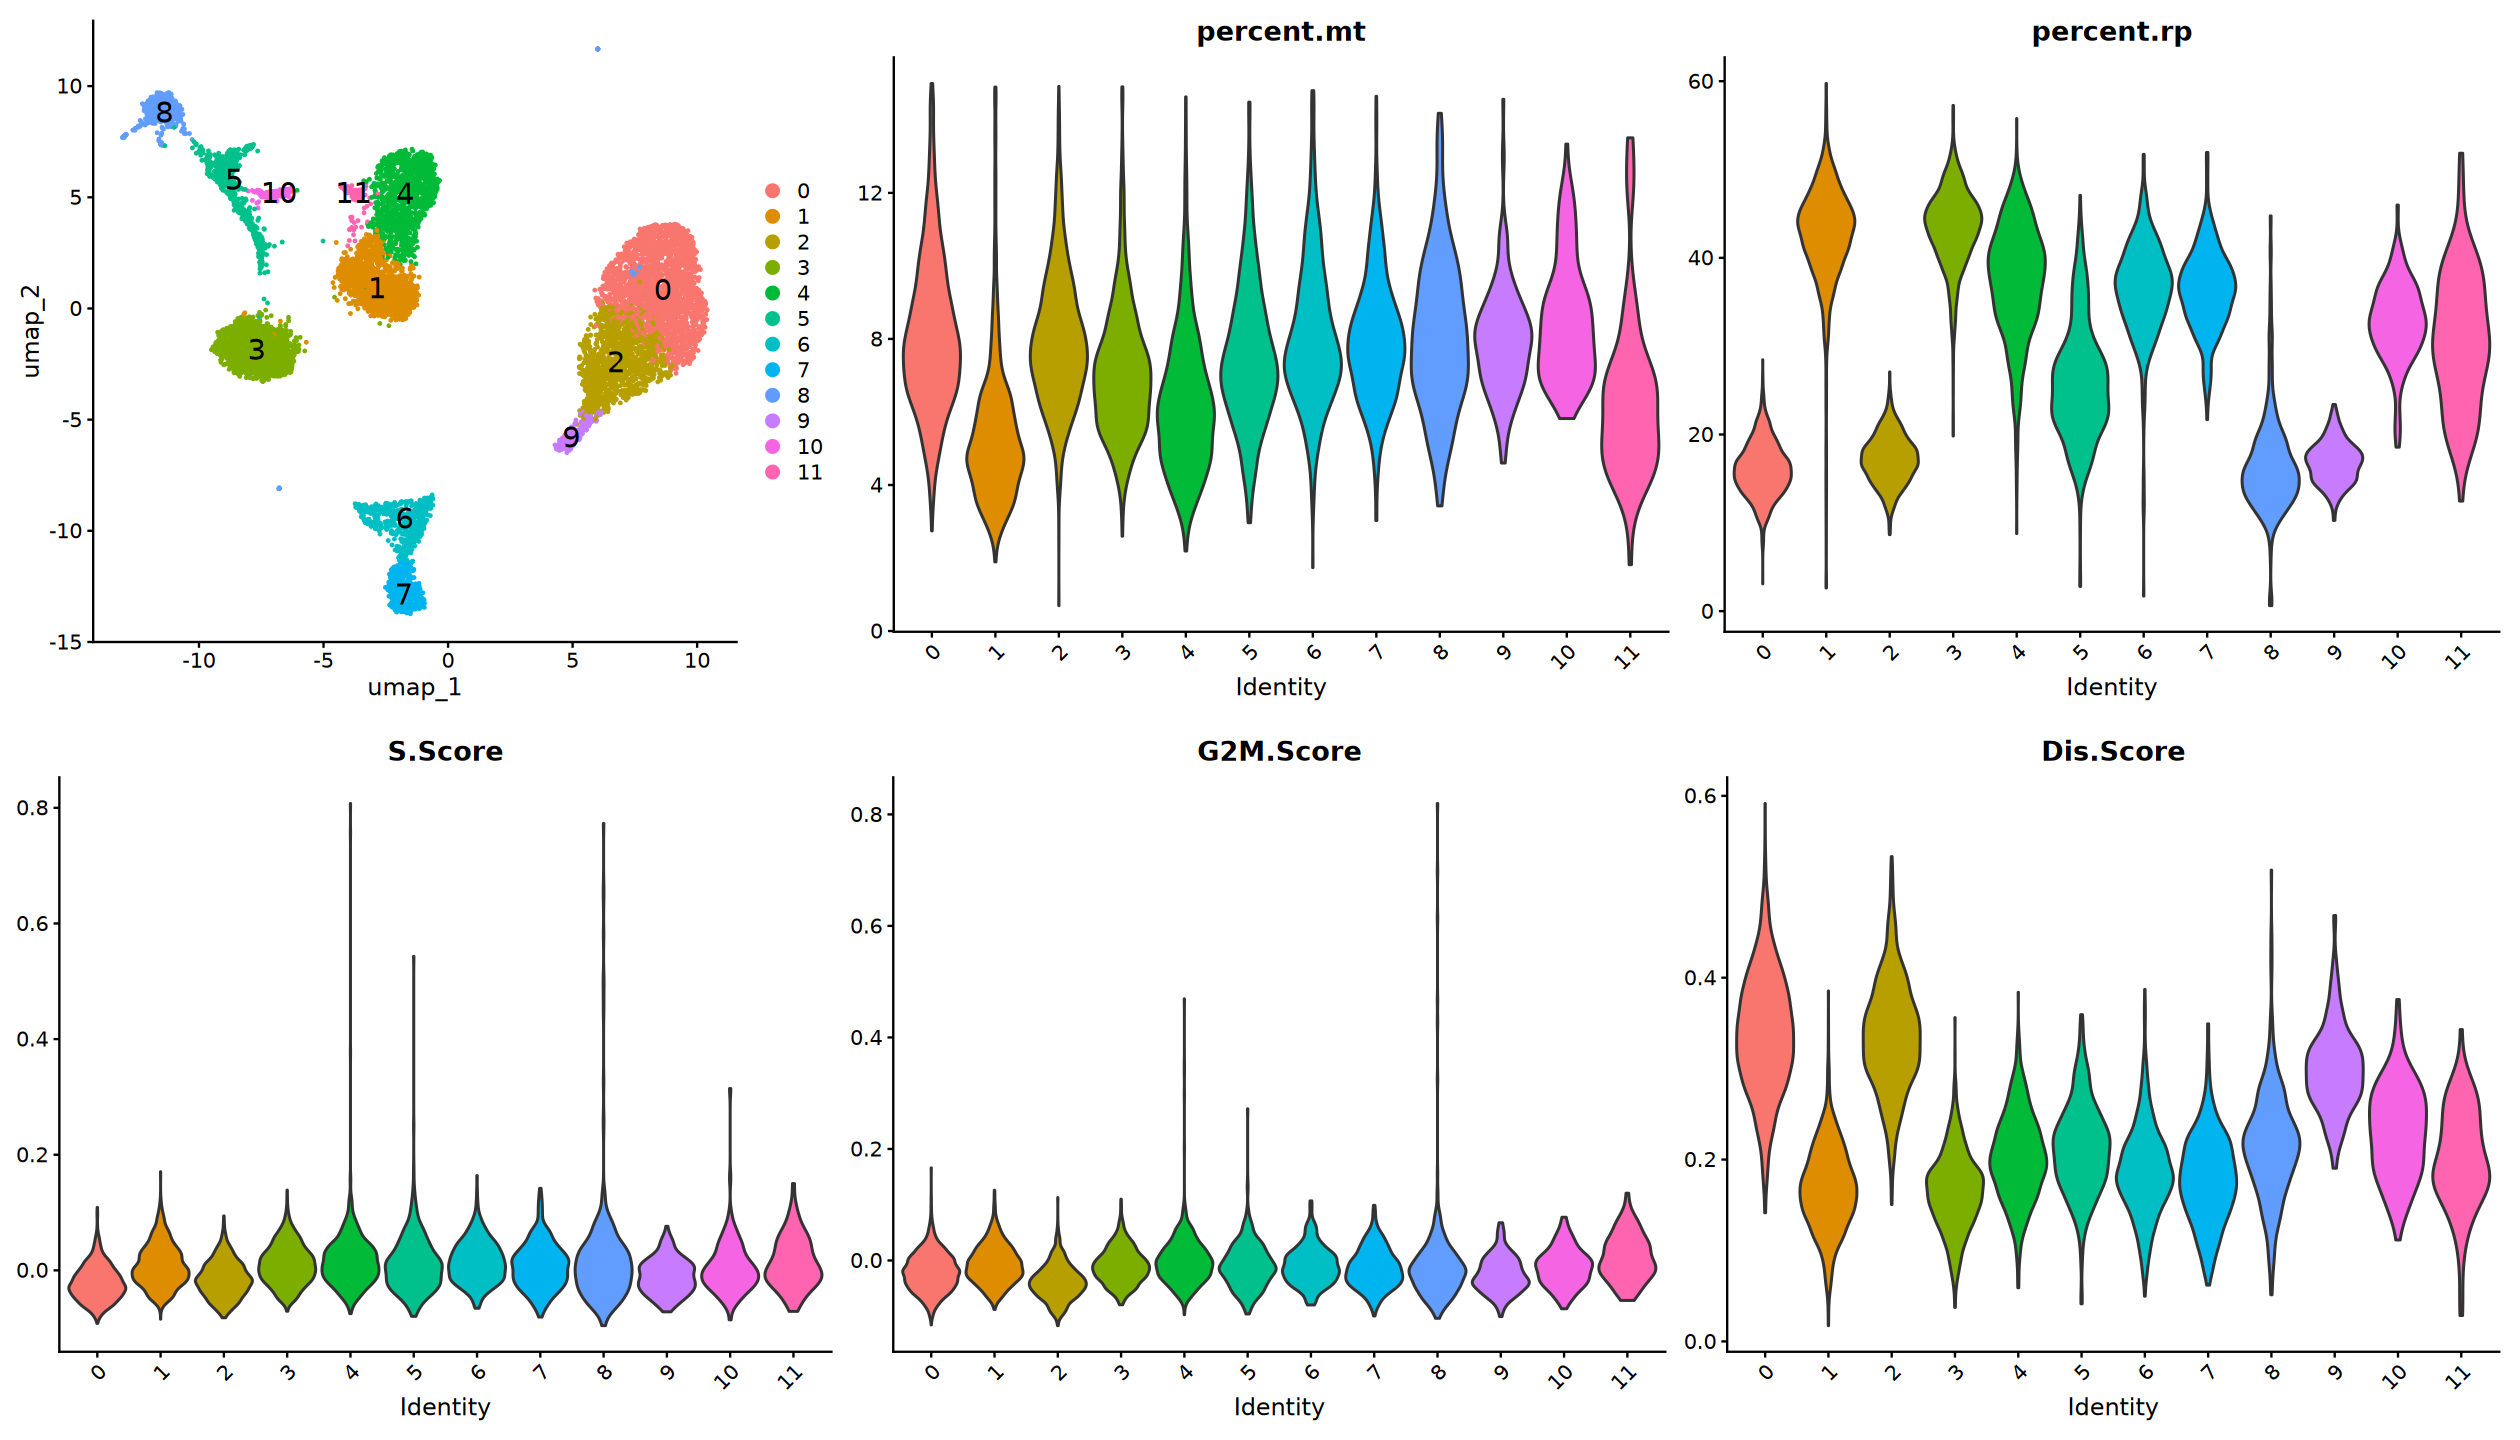

In [56]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", 
    label = TRUE, label.size = 6)
p2 <- VlnPlot(
    sc.temp, features = c("percent.mt", "percent.rp"), 
    group.by = "seurat_clusters", pt.size = 0, ncol = 2)
p3 <- VlnPlot(
    sc.temp, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, ncol = 3)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(
    plot_grid(
        p1, p2, ncol = 2, rel_widths = c(1, 2)
    ), p3, ncol = 1)

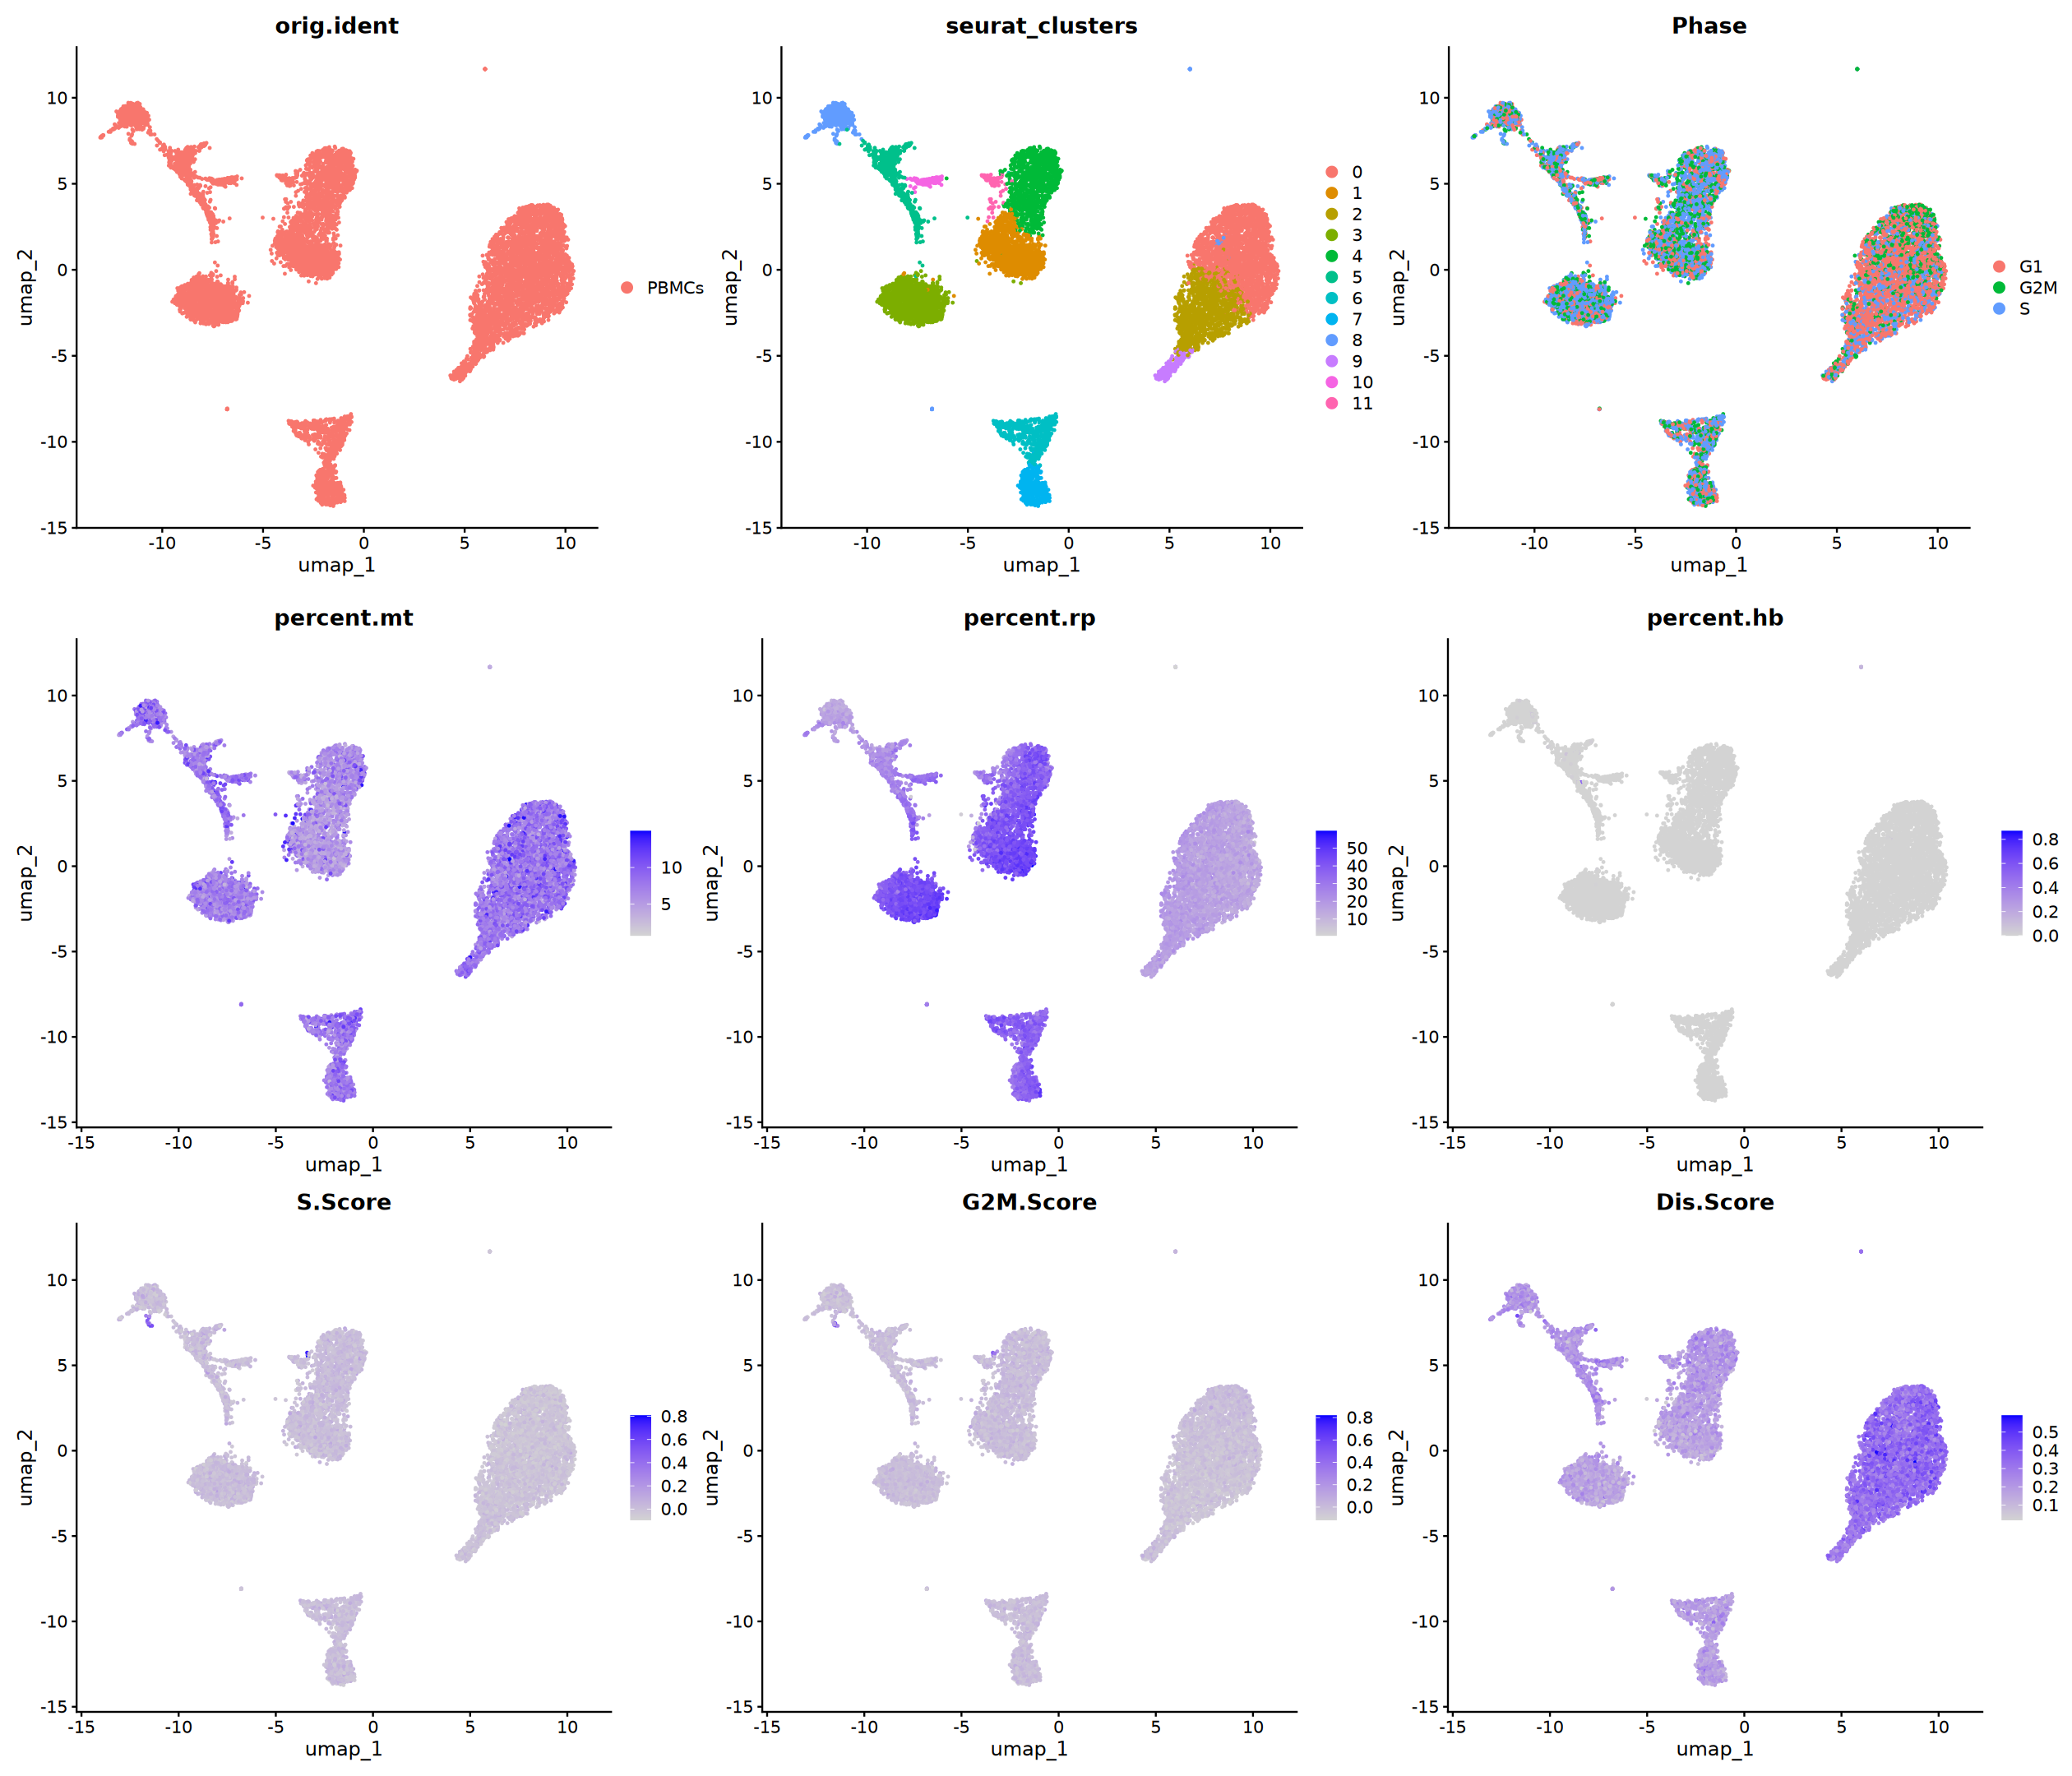

In [57]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", ncol = 3,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", ncol = 3,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(p1, p2, ncol = 1, rel_heights = c(1, 2))

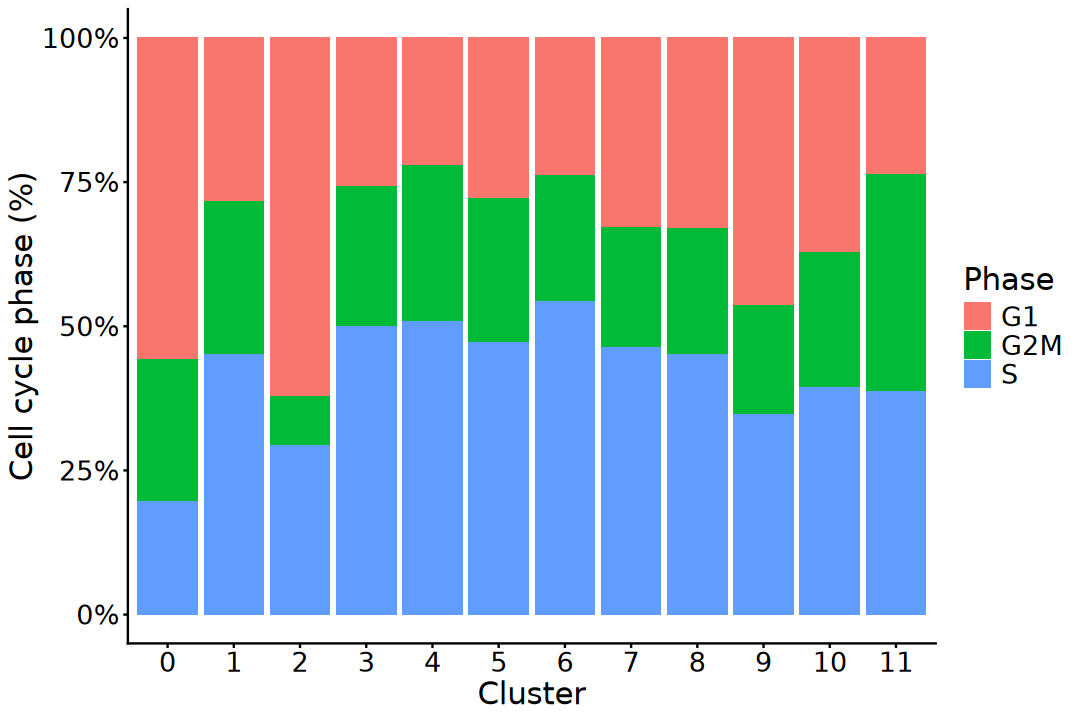

In [58]:
options(repr.plot.width = 9, repr.plot.height = 6)
table(sc.temp$seurat_clusters, sc.temp$Phase) |> 
    as.data.frame() |>
    ggplot(aes(x = Var1, y = Freq, fill = Var2)) +
        geom_bar(stat = "identity", position = "fill") +
        scale_y_continuous(labels = scales::percent_format()) +
        labs(x = "Cluster", y = "Cell cycle phase (%)", 
             fill = "Phase") +
        theme_classic() + 
        theme(axis.title = element_text(size = 18),
              axis.text = element_text(size = 16),
              legend.title = element_text(size = 18),
              legend.text = element_text(size = 16))

In [59]:
pca <- Embeddings(sc.temp, "pca")[, 1:10]

vars <- c("percent.mt", "percent.rp", "percent.hb", 
          "S.Score", "G2M.Score", "Dis.Score")

cors <- sapply(vars, function(v) {
    apply(pca, 2, cor, y = sc.temp[[v]], method = "pearson")
}) |> t()

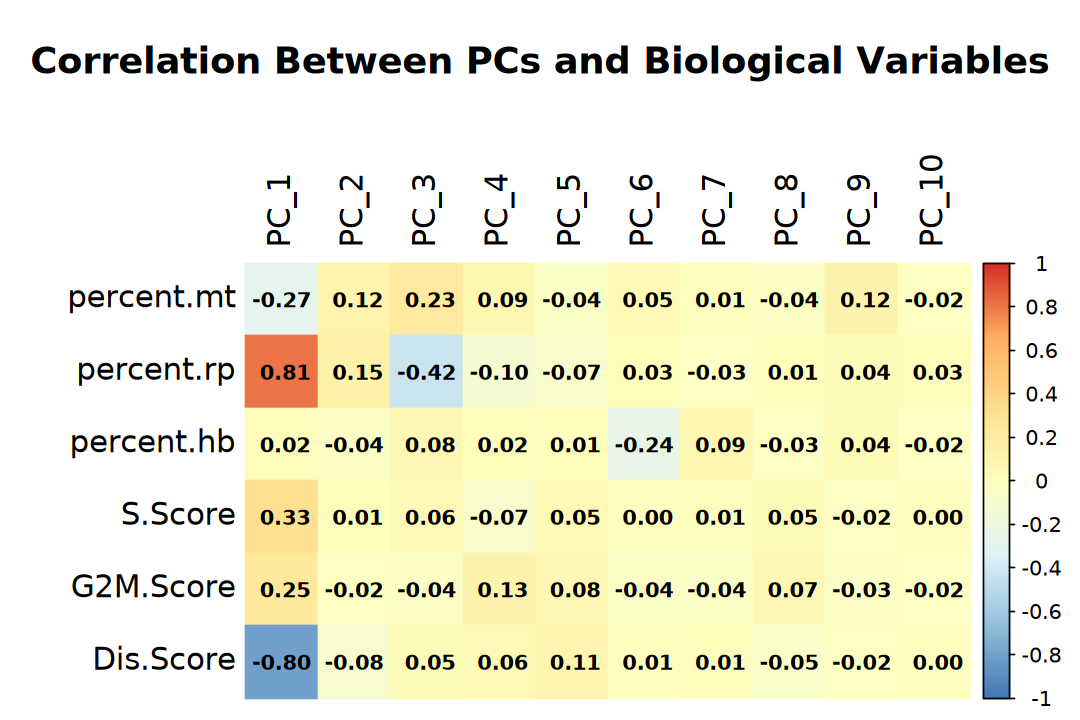

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)

gradient_colors <- colorRampPalette(
    c("#4575B4", "#91BFDB", "#E0F3F8", "#FFFFBF", 
      "#FEE090", "#FDAE61", "#D73027"))(200)

corrplot::corrplot(cors, method = "color",
                   col = gradient_colors, cl.cex = 1, col.lim = c(-1, 1),
                   title = "Correlation Between PCs and Biological Variables",
                   cex.main = 1.8, col.main = "black",
                   tl.col = "black", tl.cex = 1.5,
                   addCoef.col = "black", number.cex = 1, 
                   is.corr = FALSE, mar = c(0, 0, 5, 0))